# Selected DI reactions: individual drawings without explicit H atoms and with bond formation sites highlighted

Read `Data/Predict_DI/5_DI_selected.csv` and display all reactions in their original row order (currently 84). Each drawing shows **Diene + Ene → Product**. Blue and orange identify the two pairs of atoms forming new bonds; the corresponding product bonds are also highlighted. Remove explicit H atoms while retaining necessary NH/OH hydrogen counts and stereochemistry.

Prefer the atom mapping (AAM) in the `smiles` column of `Active_Energy_for_AttFP.csv`, matching reactant IDs, structure ID, Title, and molecular structures. Reconstruct mappings for the remaining rows using [4+2] reaction rules, accepting them only when the reconstructed product has **the same complete connectivity graph** as the supplied product. `Title` uses the original structure atom order and cannot be used directly as atom indices for the current SMILES.

Mapping reconstruction does not infer absolute stereochemistry. Drawings retain the product stereochemistry supplied in the CSV. When multiple site assignments match, record `site_assignment_count` and display one valid assignment. Symmetry-equivalent sites do not have a unique atom mapping.

In [1]:
from pathlib import Path
from collections import defaultdict
from html import escape
import csv
import json
import xml.etree.ElementTree as ET

from IPython.display import display, HTML, SVG
from rdkit import Chem, rdBase
from rdkit.Chem import rdChemReactions, rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "Data/Predict_DI/5_DI_selected.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository root or notebooks/04_discovery")
SELECTED_CSV = ROOT / "Data/Predict_DI/5_DI_selected.csv"
AAM_CSV = ROOT / "Data/DFT_Result/Active_Energy_for_AttFP.csv"
OUTPUT_DIR = ROOT / "Data/Predict_DI/5_DI_selected_reaction_drawings"
EXPORT_SVG = True
SHOW_ATOM_MAP_NUMBERS = False
START, STOP = 0, None  # Display all by default; use 0, 10 for the first ten rows (zero-based, stop exclusive)
PANEL_WIDTH, PANEL_HEIGHT = 440, 300
PANEL_GAP = 120
MOLECULE_PADDING = 0.20  # Leave more whitespace around each molecular structure
COLORS = [(0.20, 0.55, 0.95), (1.00, 0.58, 0.20)]
print("RDKit:", rdBase.rdkitVersion)
print("Input:", SELECTED_CSV)

RDKit: 2024.03.3
Input: D:\OneDrive_all\OneDrive\Work\work_part\9.CycloAddGenerator\Data\Predict_DI\5_DI_selected.csv


## Load reactions in their original order and the AAM reference

Preserve the original order and retain duplicate reactions as separate entries. The historical AAM reference format is `mapped_diene.mapped_ene.mapped_product`; the final component is the product, so these are not three reactants.

In [2]:
with SELECTED_CSV.open(newline="", encoding="utf-8-sig") as f:
    rows = list(csv.DictReader(f))
with AAM_CSV.open(newline="", encoding="utf-8-sig") as f:
    reference_rows = list(csv.DictReader(f))
required = {"Diene", "Ene", "Product", "Diene_Index", "Ene_Index", "Structure_Id", "Title"}
if not rows or not required.issubset(rows[0]):
    raise ValueError("The selection CSV is empty or missing required fields")

def reaction_key(row):
    return (int(row["Diene_Index"]), int(row["Ene_Index"]),
            int(row.get("Structure_Id", row.get("Structure_id"))),
            " ".join(row["Title"].split()))

references = defaultdict(list)
for row in reference_rows:
    references[reaction_key(row)].append(row)
print(f"Selected reactions: {len(rows)}; AAM reference rows: {len(reference_rows)}")

Selected reactions: 84; AAM reference rows: 8273


## Validate atom mappings and bond formation sites

Validate each mapping for complete heavy-atom coverage, unique map numbers, and element conservation. The product must contain exactly two new intermolecular bonds relative to the reactants. Highlight only validated sites.

In [3]:
def parse_mol(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Cannot parse SMILES: {smiles}")
    return Chem.RemoveHs(mol)


def graph_key(mol):
    mol = Chem.Mol(mol)
    for atom in mol.GetAtoms():
        atom.SetAtomMapNum(0)
    return Chem.MolToSmiles(mol, isomericSmiles=False)


def mapped_bonds(mols):
    return {tuple(sorted((b.GetBeginAtom().GetAtomMapNum(),
                          b.GetEndAtom().GetAtomMapNum())))
            for m in mols for b in m.GetBonds()}


def validate_mapping(diene, ene, product):
    def elements(mols):
        result = {}
        for mol in mols:
            for atom in mol.GetAtoms():
                number = atom.GetAtomMapNum()
                if number <= 0 or number in result:
                    raise ValueError("Missing or duplicate heavy-atom map numbers in AAM")
                result[number] = atom.GetAtomicNum()
        return result
    if elements([diene, ene]) != elements([product]):
        raise ValueError("Heavy-atom mappings are not conserved between reactants and product")
    formed = sorted(mapped_bonds([product]) - mapped_bonds([diene, ene]))
    dmaps = {a.GetAtomMapNum() for a in diene.GetAtoms()}
    if len(formed) != 2 or not all((a in dmaps) != (b in dmaps) for a, b in formed):
        raise ValueError("Expected exactly two newly formed intermolecular bonds")
    return formed


RULES = [rdChemReactions.ReactionFromSmarts(s) for s in [
    "[*:1]=[*:2]-[*:3]=[*:4].[*:5]=[*:6]>>[*:1]1-[*:2]=[*:3]-[*:4]-[*:6]-[*:5]-1",
    "[*:1]=[*:2]-[*:3]=[*:4].[*:5]#[*:6]>>[*:1]1-[*:2]=[*:3]-[*:4]-[*:6]=[*:5]-1",
]]


def infer_mapping(row):
    diene, ene, target = [parse_mol(row[k]) for k in ("Diene", "Ene", "Product")]
    offset = diene.GetNumAtoms()
    for mol, start in [(diene, 0), (ene, offset)]:
        for atom in mol.GetAtoms():
            atom.SetAtomMapNum(start + atom.GetIdx() + 1)
    kd, ke = Chem.Mol(diene), Chem.Mol(ene)
    Chem.Kekulize(kd, clearAromaticFlags=True)
    Chem.Kekulize(ke, clearAromaticFlags=True)
    candidates = {}
    for rule in RULES:
        for candidate, in rule.RunReactants((kd, ke)):
            try:
                Chem.SanitizeMol(candidate)
            except (ValueError, RuntimeError):
                continue
            for atom in candidate.GetAtoms():
                # Reactive atoms carry template maps; spectator atoms retain input maps.
                if atom.HasProp("old_mapno"):
                    role = atom.GetIntProp("old_mapno")
                    atom.SetAtomMapNum(atom.GetIntProp("react_atom_idx") + 1
                                       + (offset if role > 4 else 0))
            if graph_key(candidate) != graph_key(target):
                continue
            query = Chem.Mol(candidate)
            for atom in query.GetAtoms():
                atom.SetAtomMapNum(0)
            match = target.GetSubstructMatch(query, useChirality=False)
            if len(match) != target.GetNumAtoms():
                continue
            product = Chem.Mol(target)  # Retain the supplied product stereochemistry.
            for query_index, target_index in enumerate(match):
                product.GetAtomWithIdx(target_index).SetAtomMapNum(
                    candidate.GetAtomWithIdx(query_index).GetAtomMapNum())
            formed = validate_mapping(diene, ene, product)
            candidates.setdefault(tuple(formed), (diene, ene, product, formed))
    if not candidates:
        raise ValueError("The reconstructed [4+2] product does not match the CSV product; reaction sites cannot be assigned")
    return (*candidates[sorted(candidates)[0]], "connectivity reconstruction", len(candidates))


def get_mapping(row):
    for reference in references.get(reaction_key(row), []):
        parts = reference.get("smiles", "").split(".")
        if len(parts) != 3:
            continue
        mapped = [parse_mol(s) for s in parts]
        supplied = [parse_mol(row[k]) for k in ("Diene", "Ene", "Product")]
        if any(graph_key(a) != graph_key(b) for a, b in zip(mapped, supplied)):
            continue
        # Transfer reference maps onto the selected structures, preserving CSV stereo.
        transferred = []
        for source, target in zip(mapped, supplied):
            query = Chem.Mol(source)
            for atom in query.GetAtoms():
                atom.SetAtomMapNum(0)
            match = target.GetSubstructMatch(query, useChirality=False)
            if len(match) != target.GetNumAtoms():
                break
            for a, b in enumerate(match):
                target.GetAtomWithIdx(b).SetAtomMapNum(source.GetAtomWithIdx(a).GetAtomMapNum())
            transferred.append(target)
        if len(transferred) == 3:
            formed = validate_mapping(*transferred)
            return (*transferred, formed, "DFT AAM reference", 1)
    return infer_mapping(row)


records = []
for position, row in enumerate(rows, 1):
    try:
        diene, ene, product, formed, source, count = get_mapping(row)
    except Exception as exc:
        raise ValueError(f"Site assignment failed for row {position} (index={row.get('index')})") from exc
    records.append(dict(position=position, row=row, mols=(diene, ene, product),
                        formed=formed, source=source, site_assignment_count=count))
print(f"All {len(records)} reactions passed connectivity and bond formation site checks.")
print("Using the DFT AAM reference: ", sum(r["source"] == "DFT AAM reference" for r in records))
print("Reactions with multiple valid site assignments: ", sum(r["site_assignment_count"] > 1 for r in records))

All 84 reactions passed connectivity and bond formation site checks.
Using the DFT AAM reference:  5
Reactions with multiple valid site assignments:  29


## RDKit Draw: display and export individual reactions

Display all reactions by default and save individual SVG drawings in `Data/Predict_DI/5_DI_selected_reaction_drawings/`, together with an `index.html` gallery in row order and a `manifest.csv` containing atom mappings, sites, and mapping sources. Blue and orange distinguish the two new bonds and do not imply a reaction sequence. Set `SHOW_ATOM_MAP_NUMBERS=True` to display atom map numbers or `EXPORT_SVG=False` to disable file export.

Molecules use extra surrounding whitespace to keep them smaller than the reaction panels. Plus signs and arrows are enlarged. Atoms and bonds are black except for the two highlighted reaction sites; R/S annotations are hidden, while stereochemical bond directions are retained.


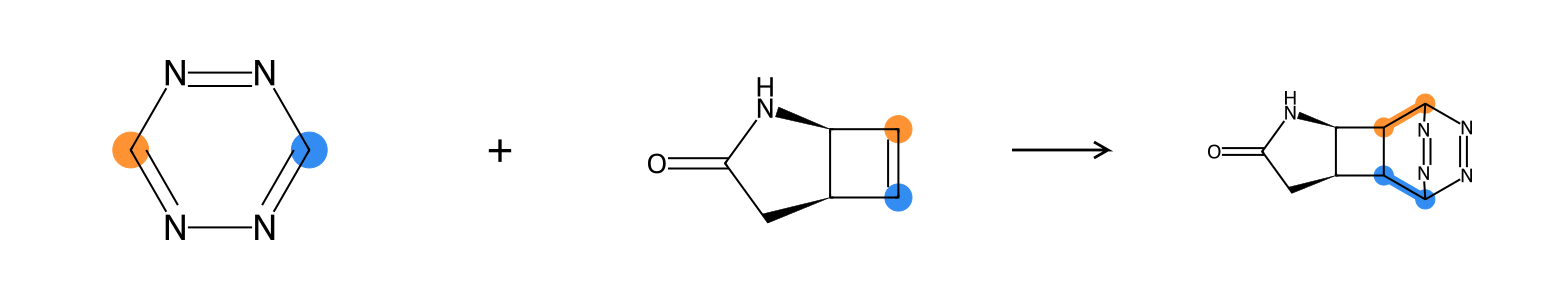

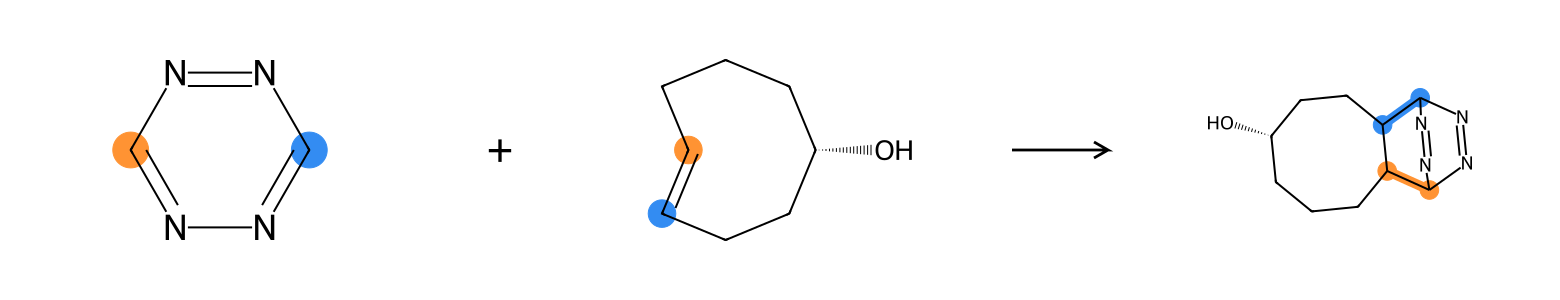

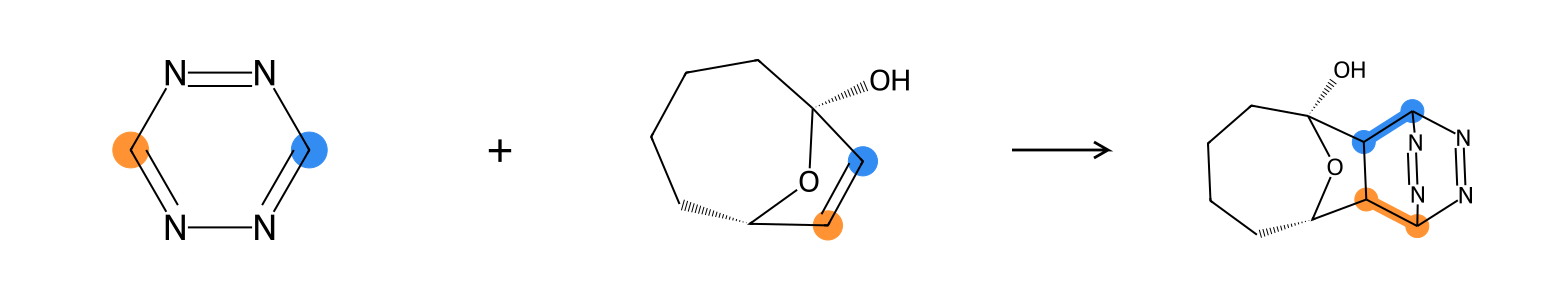

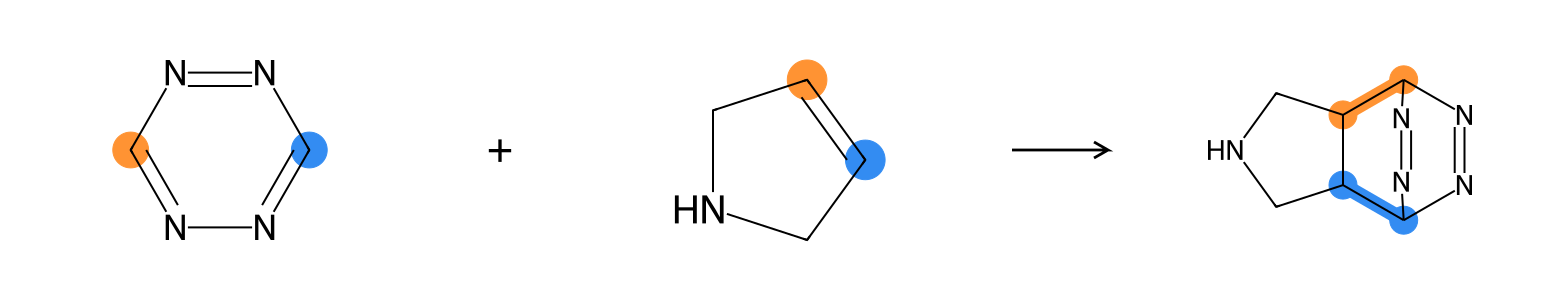

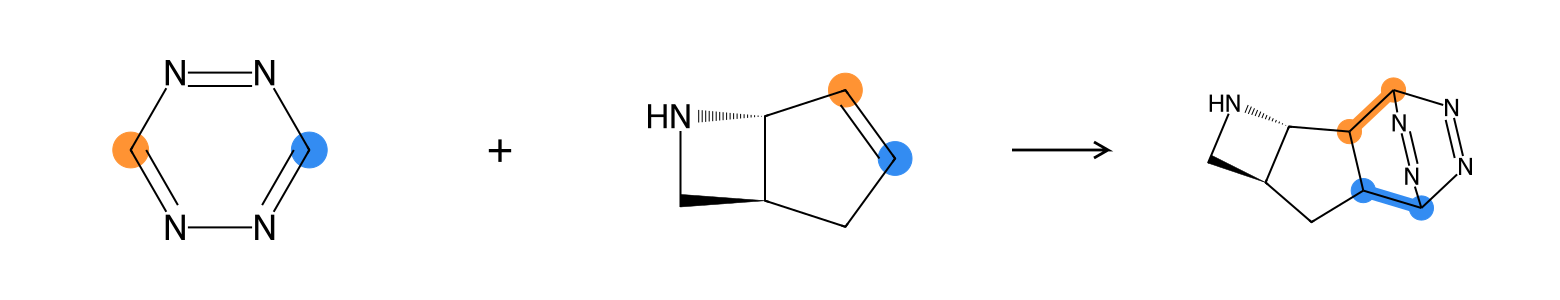

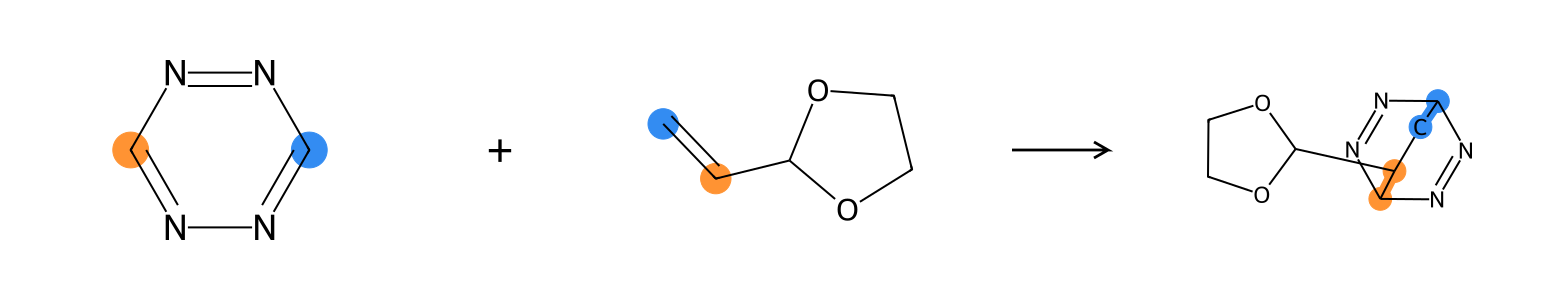

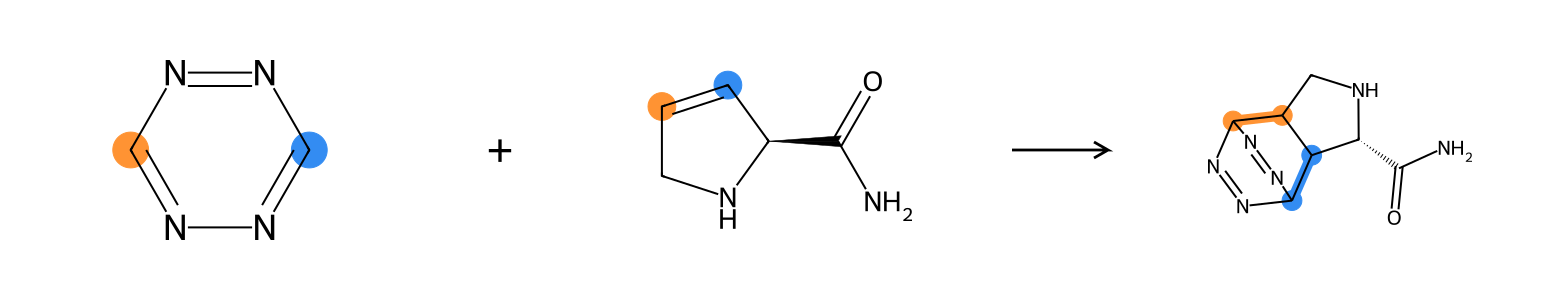

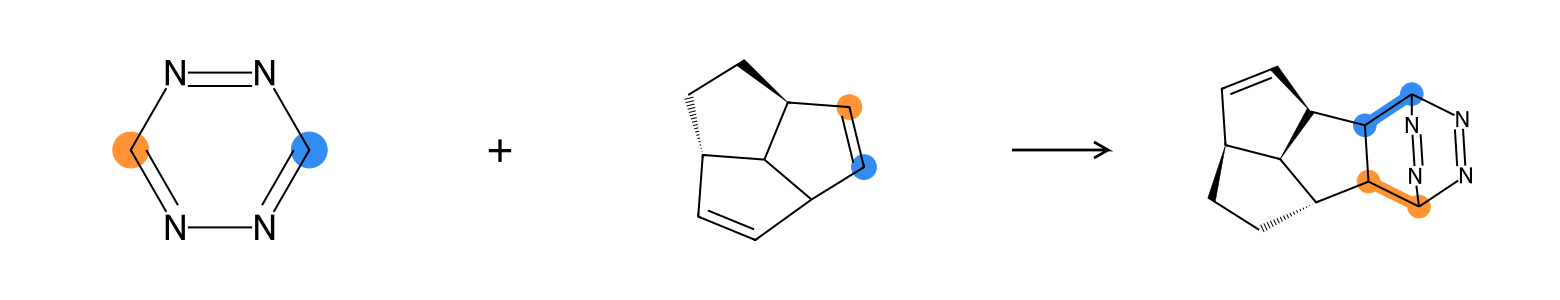

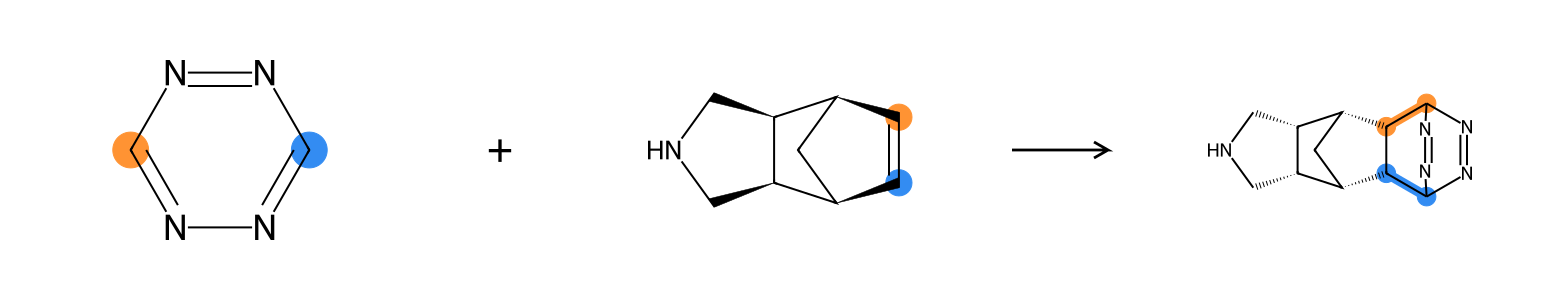

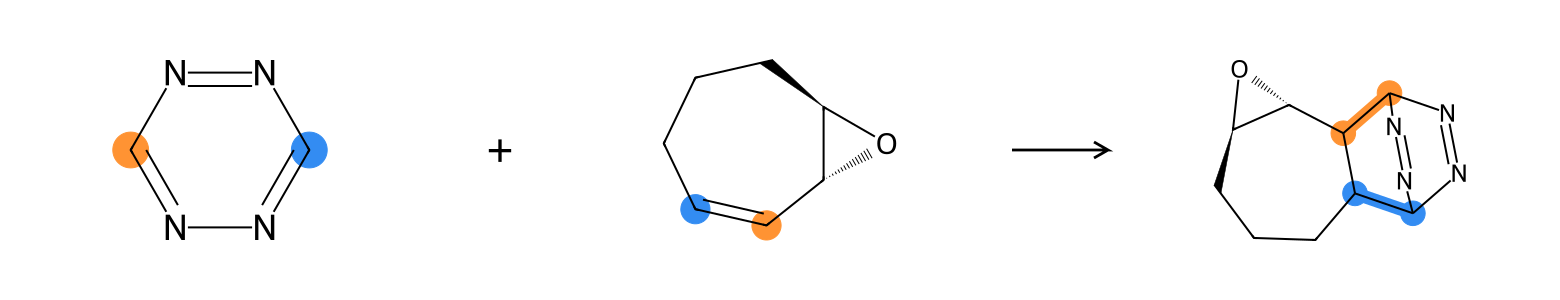

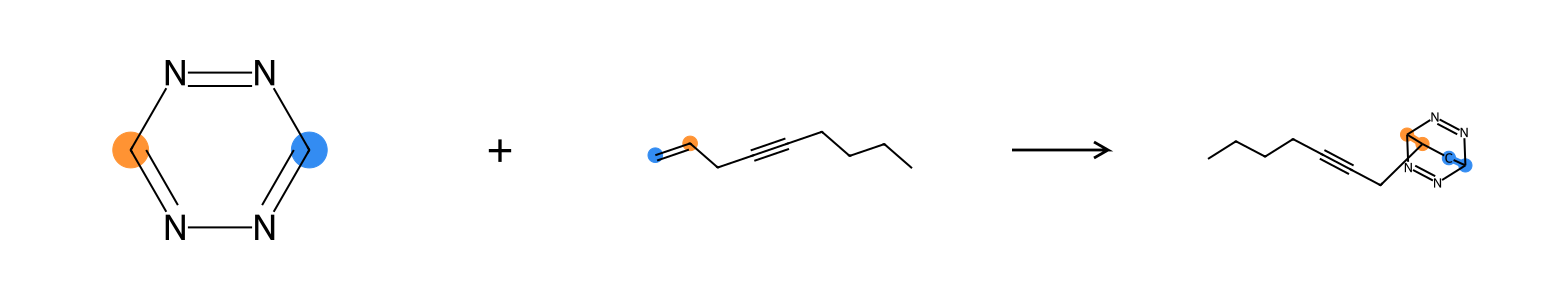

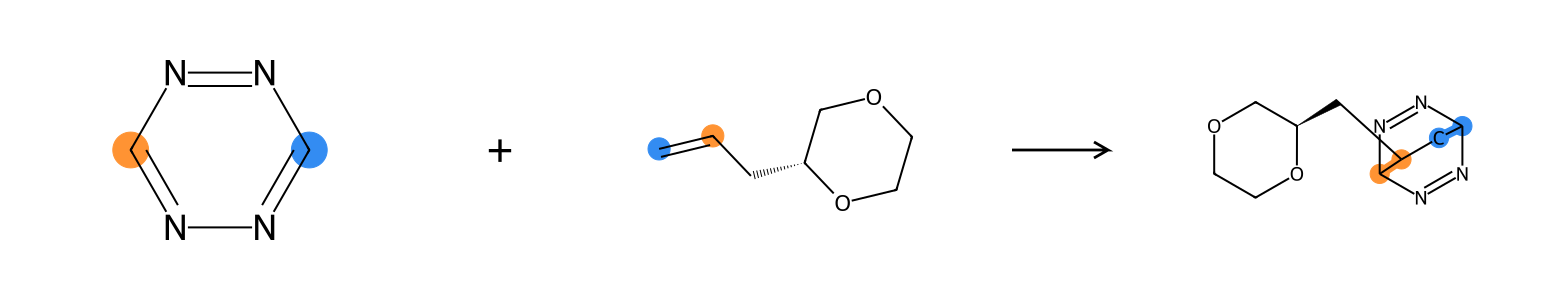

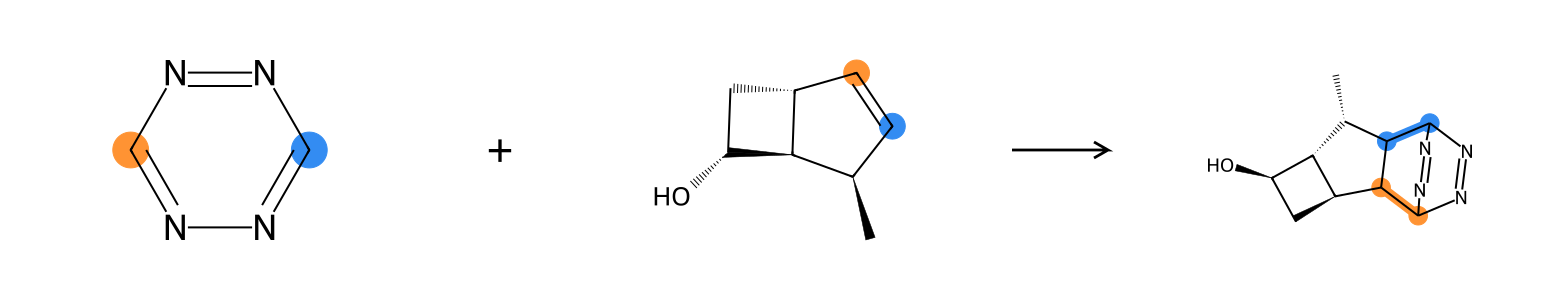

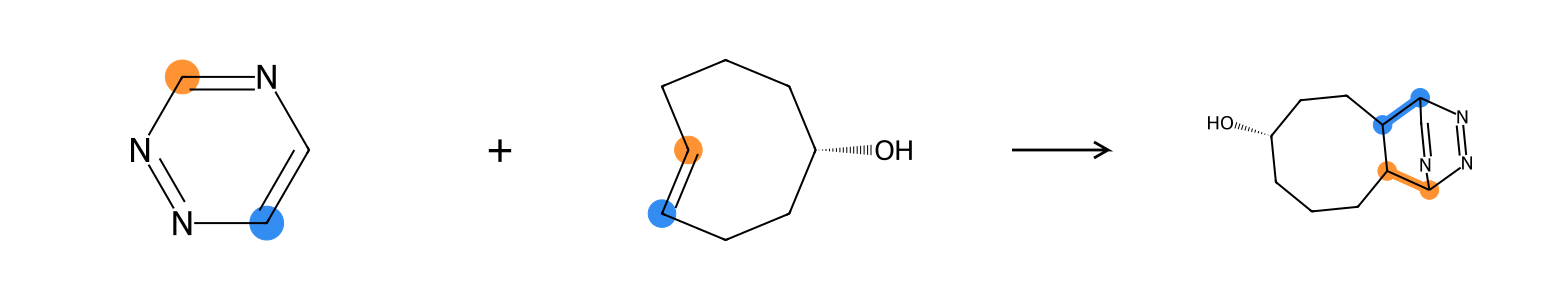

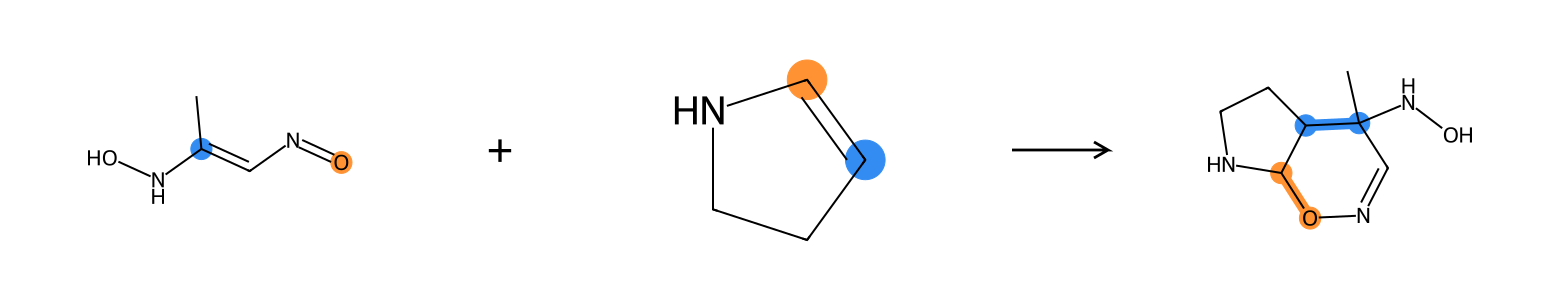

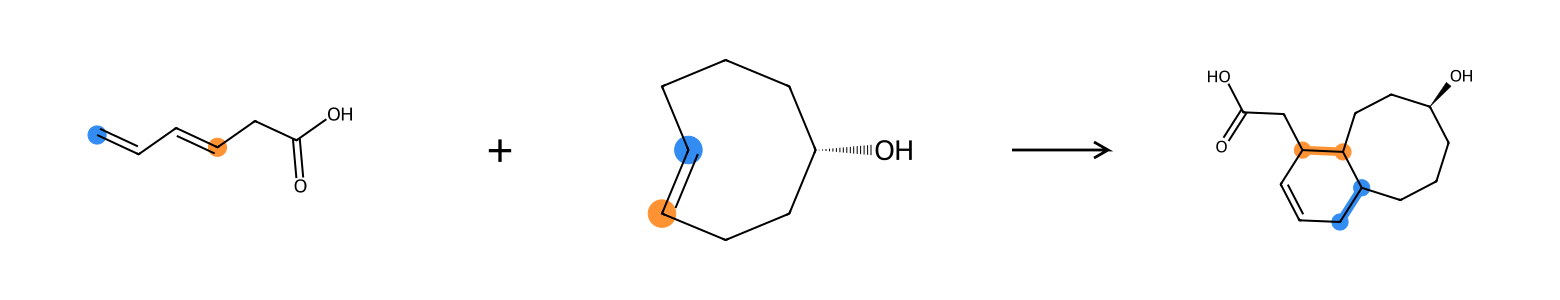

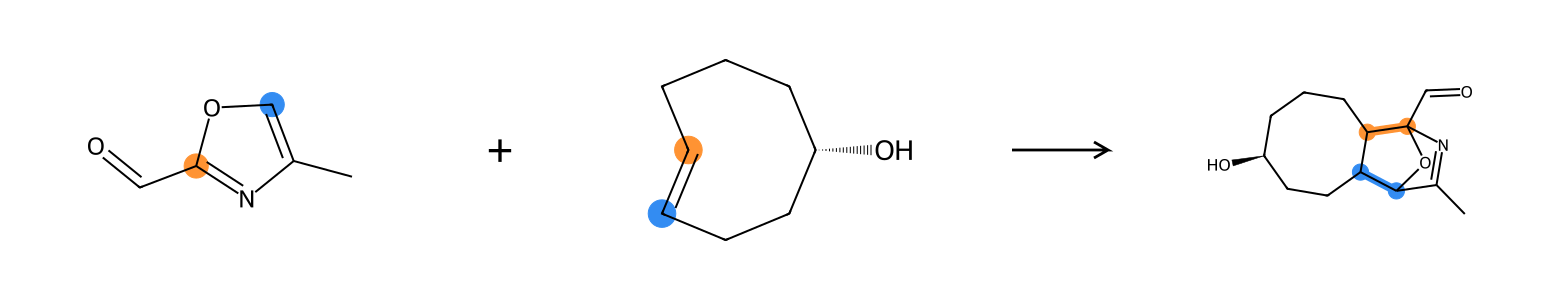

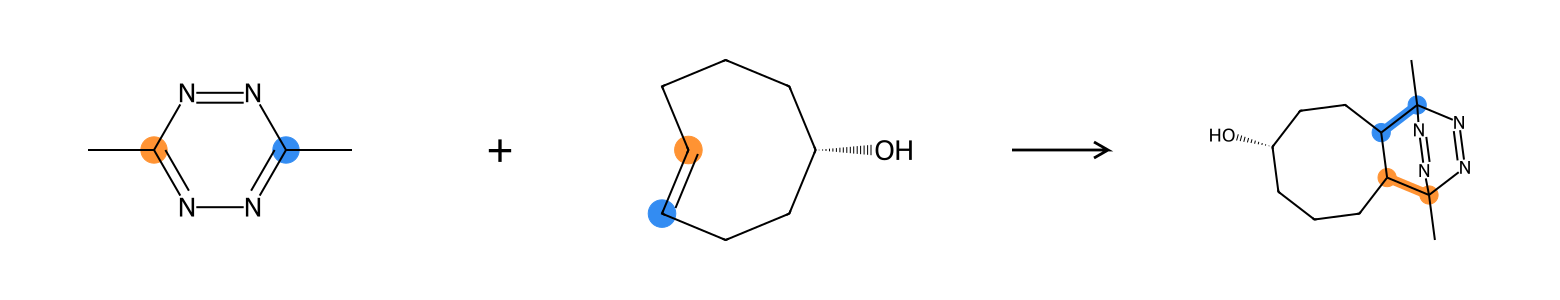

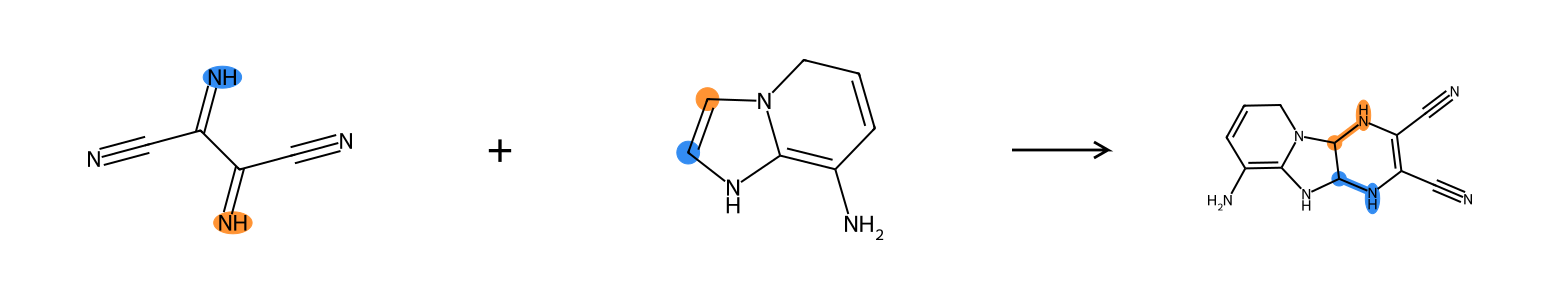

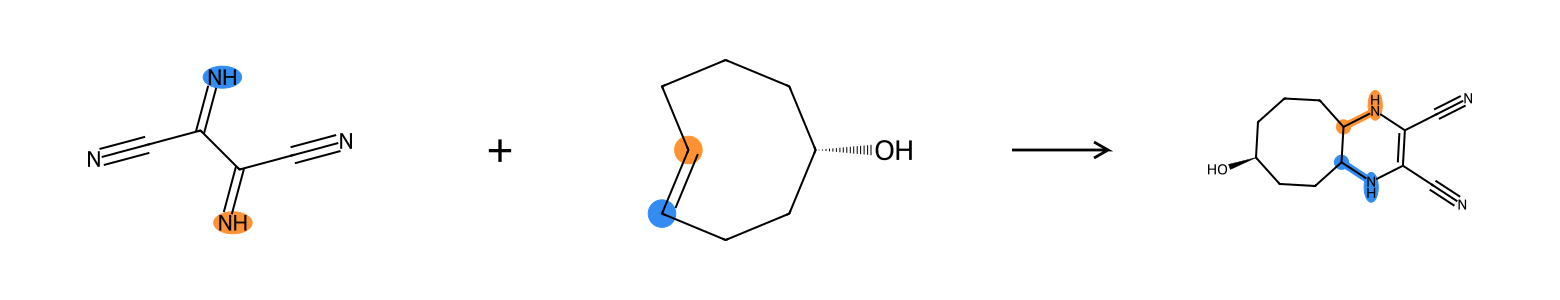

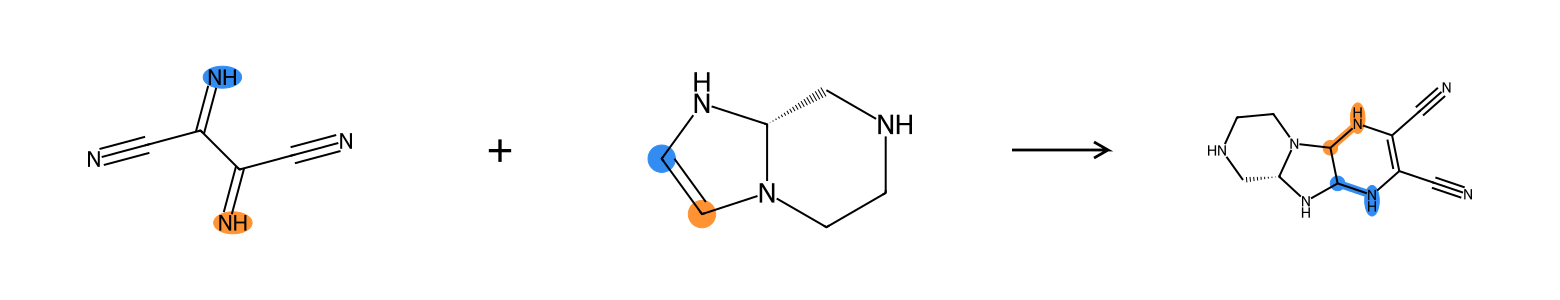

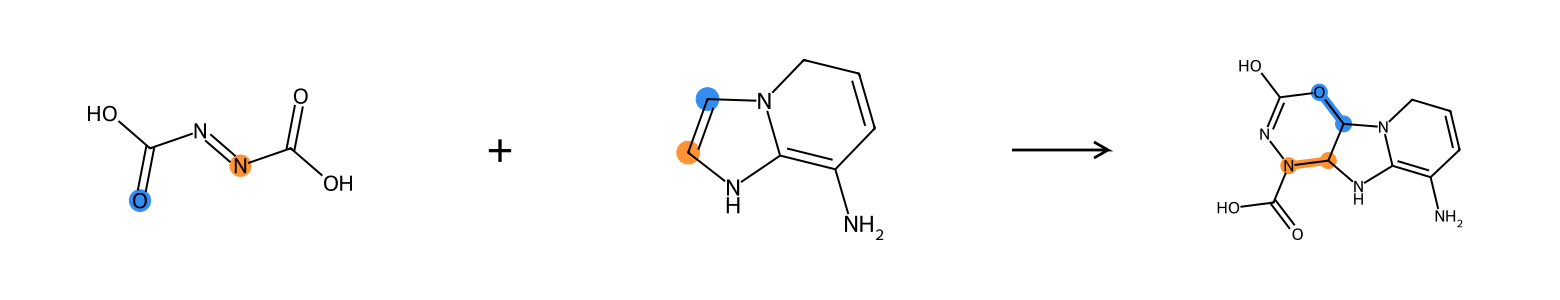

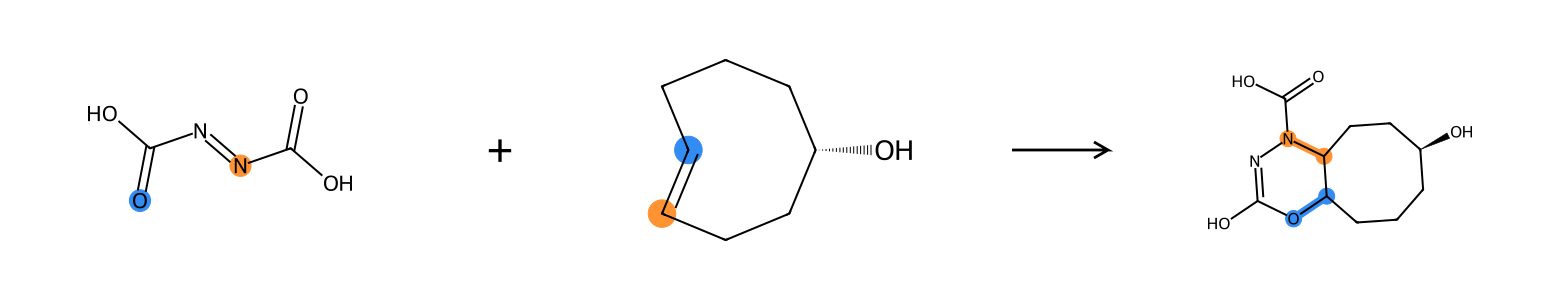

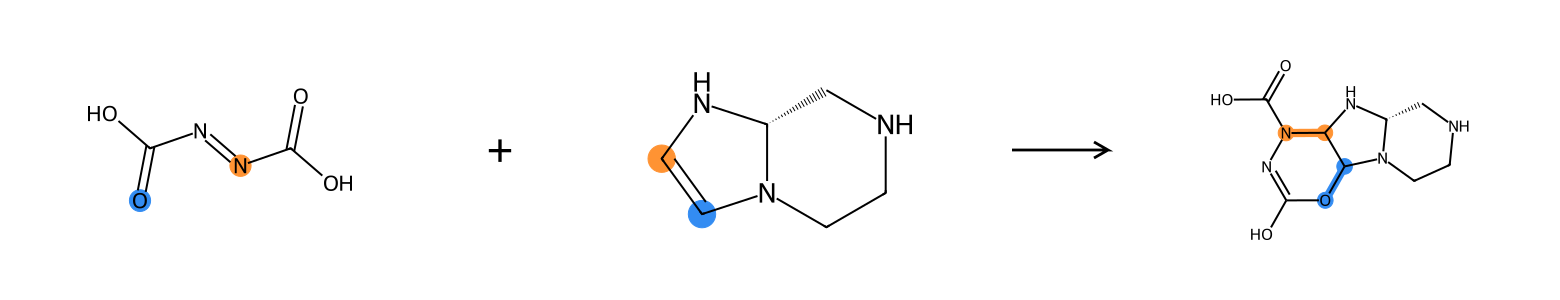

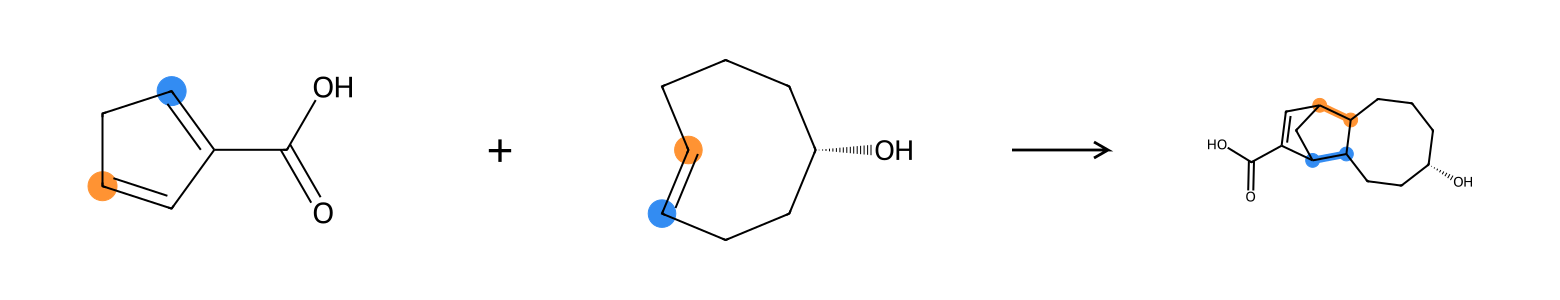

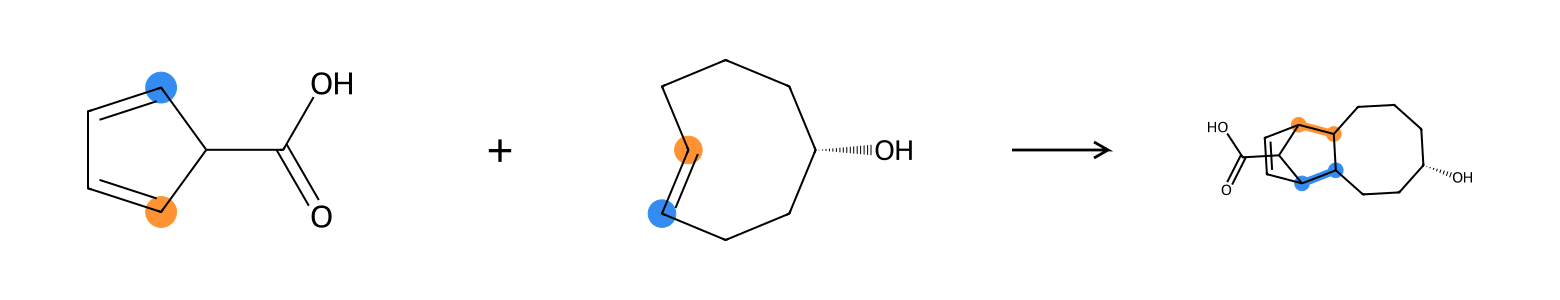

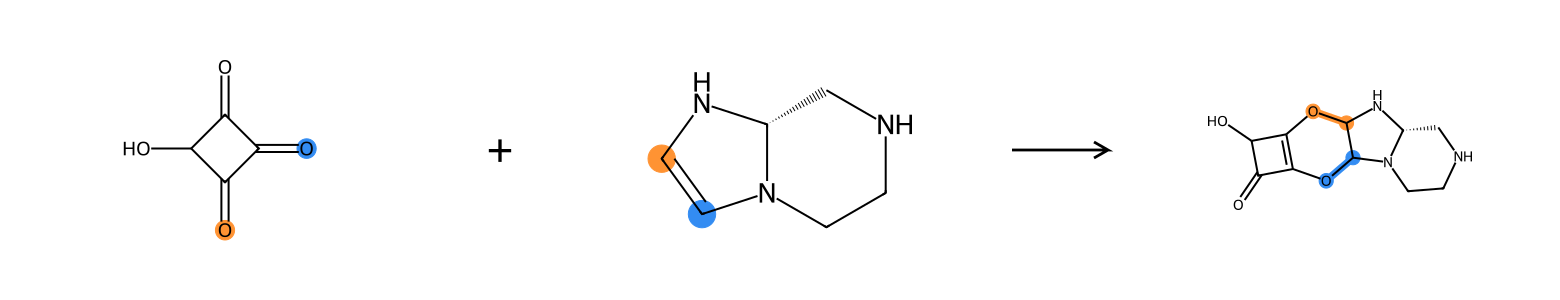

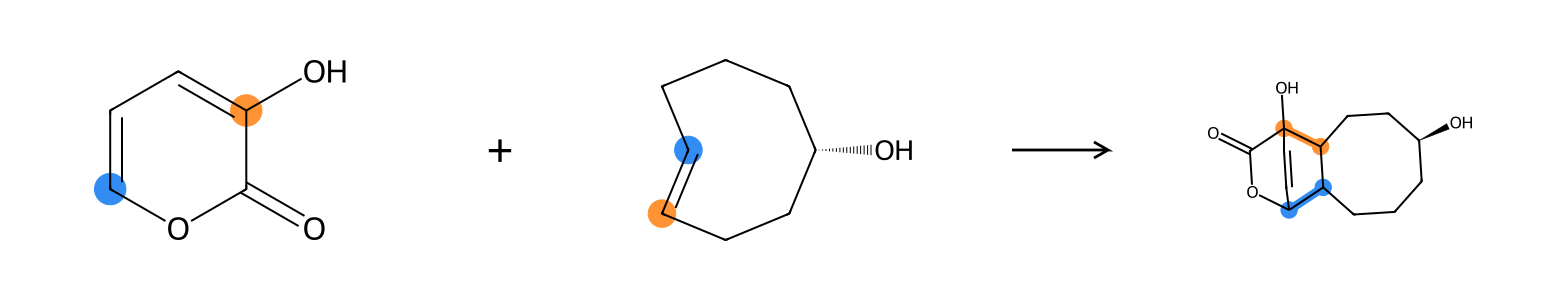

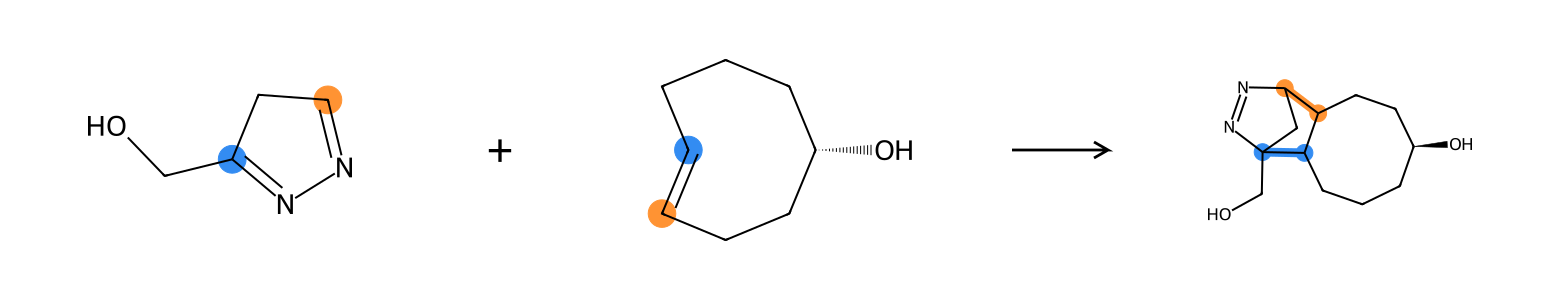

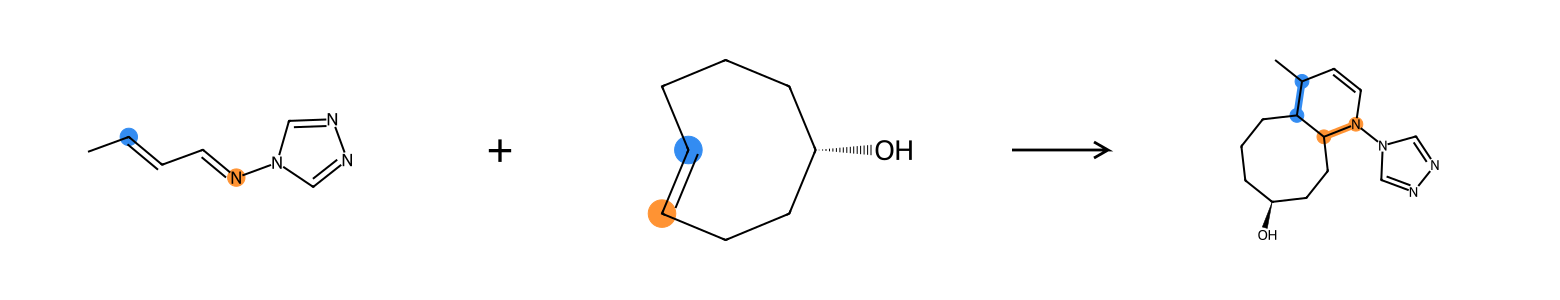

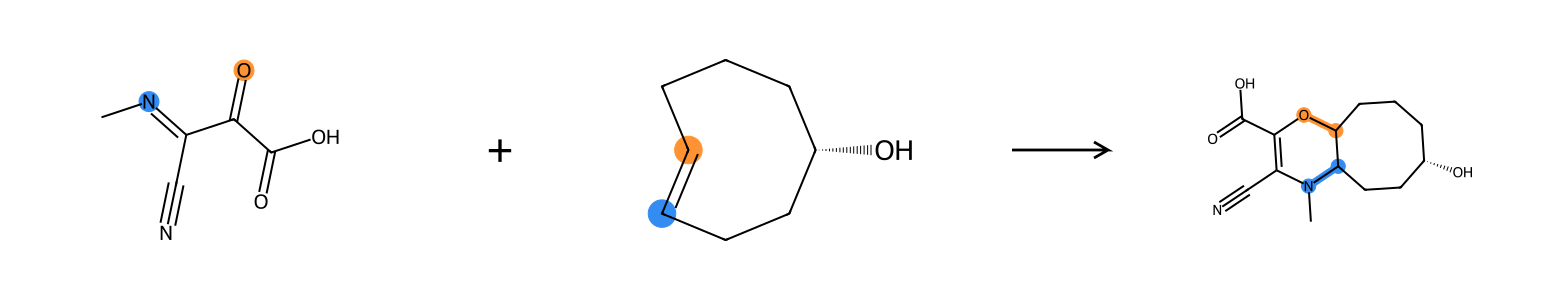

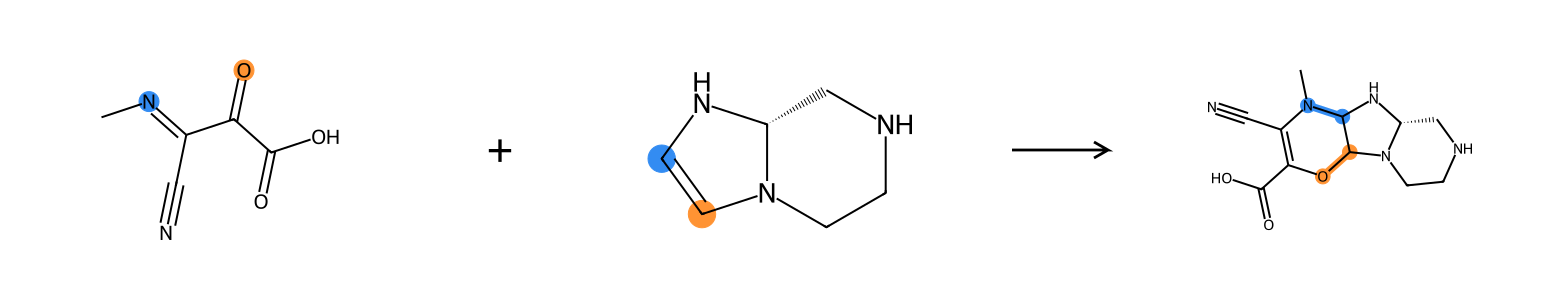

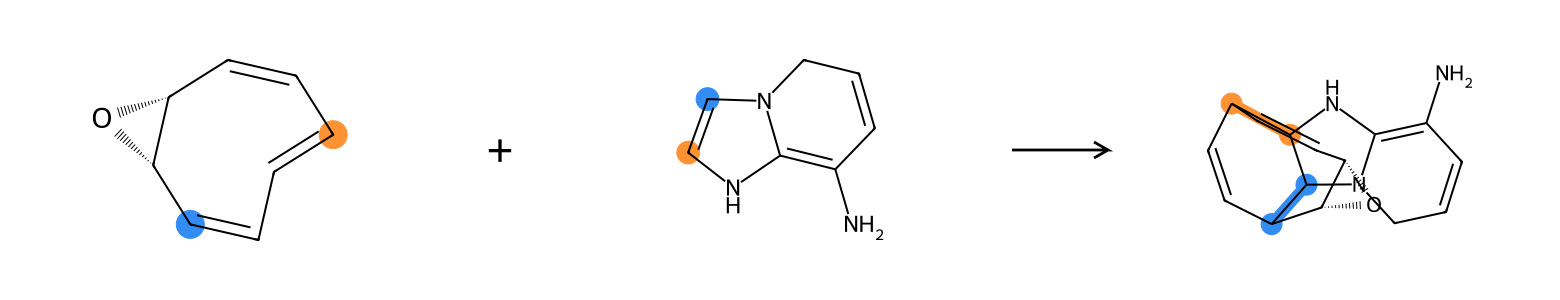

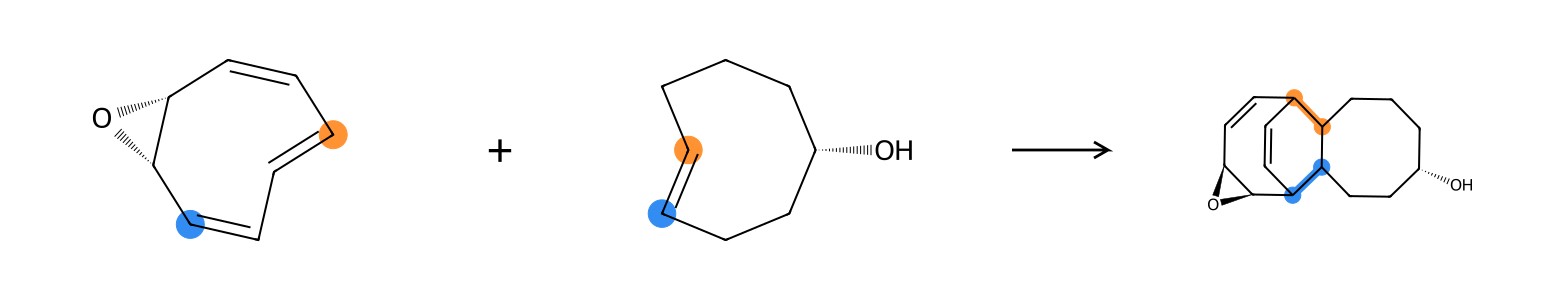

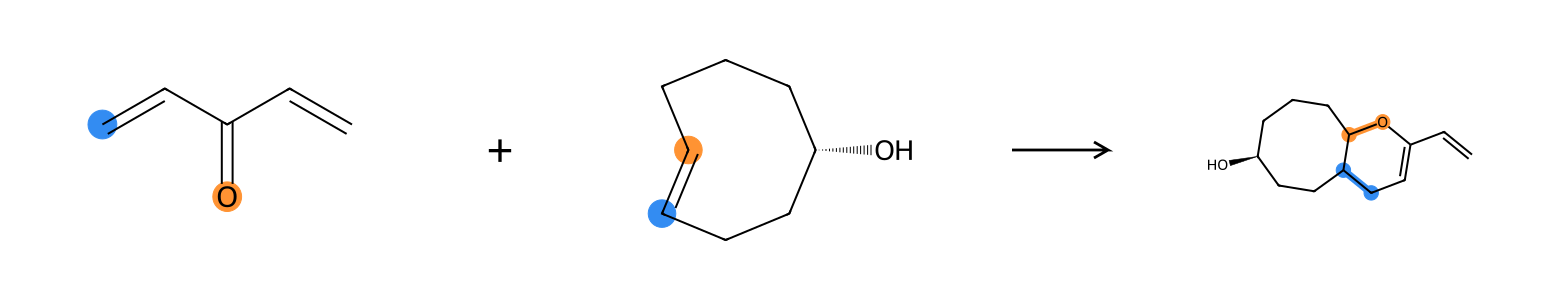

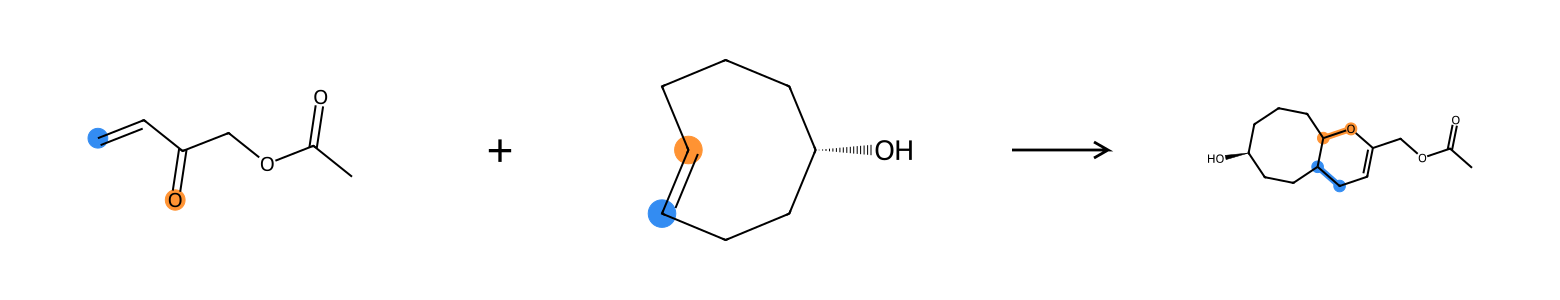

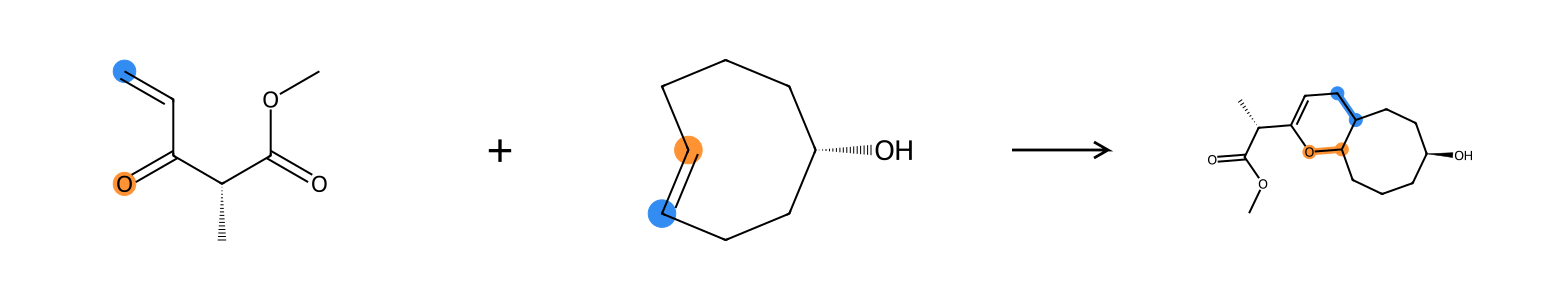

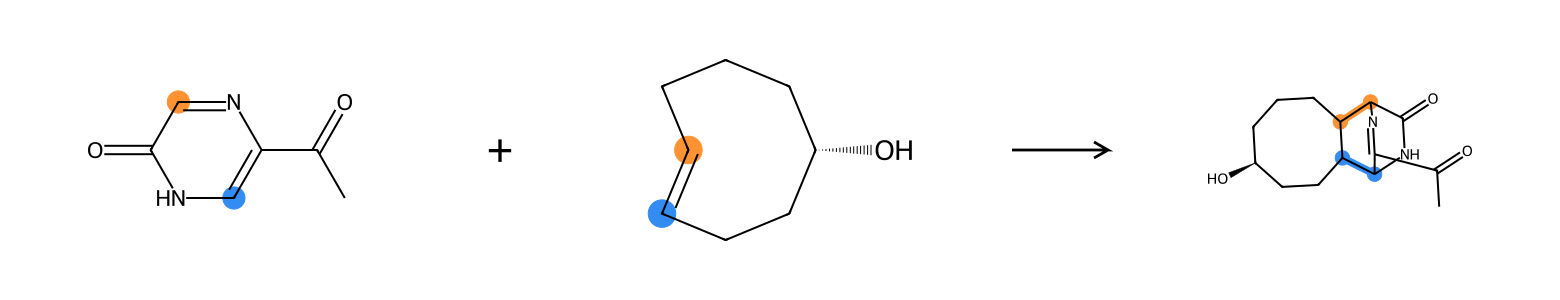

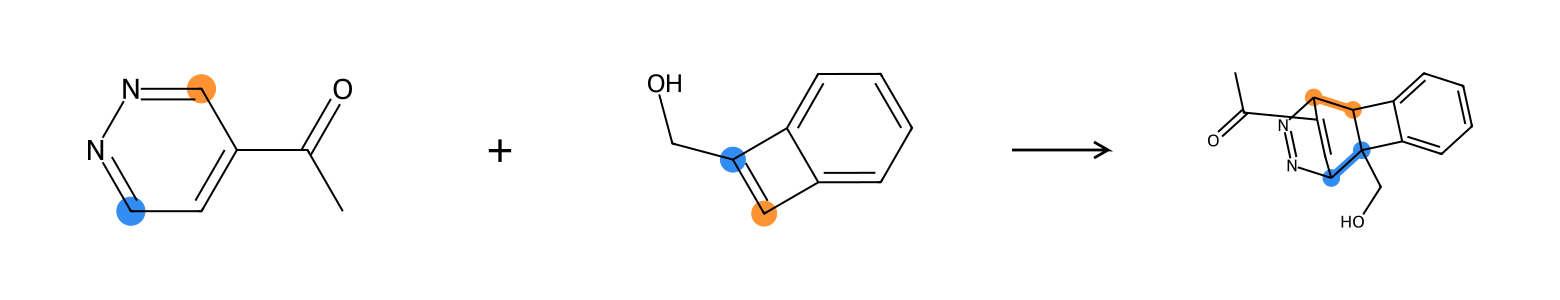

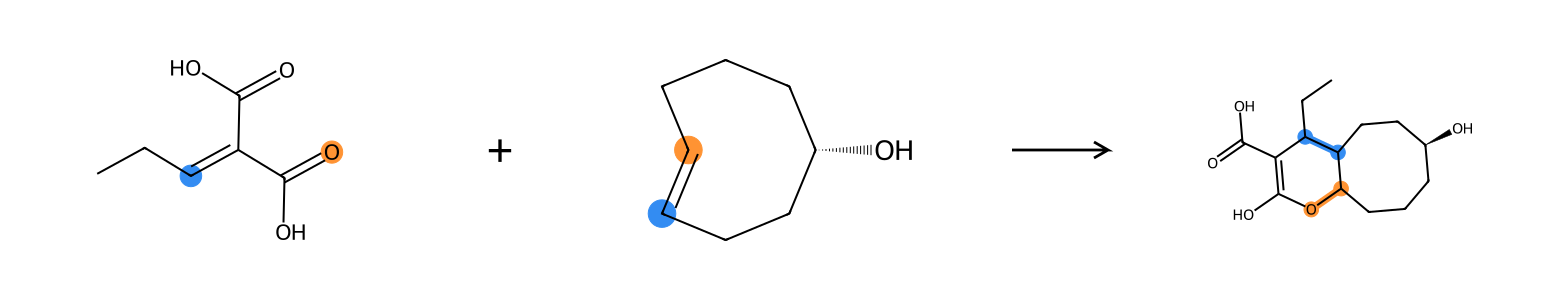

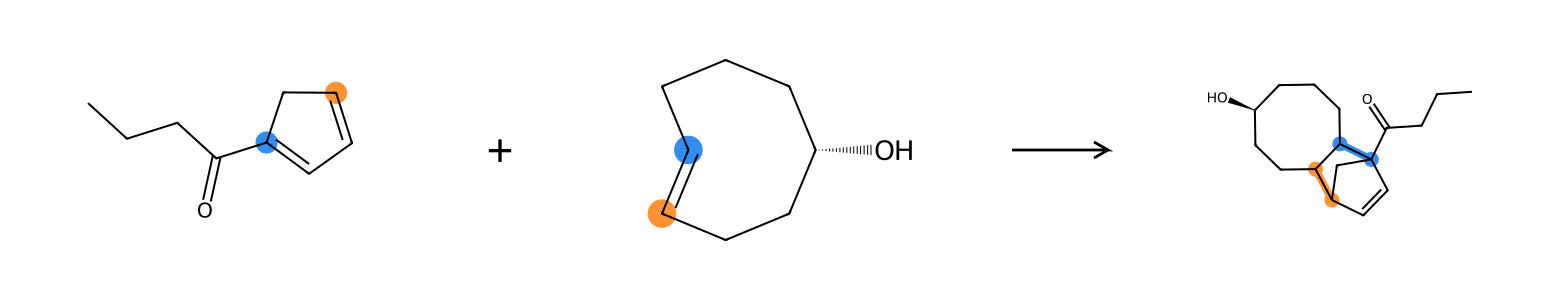

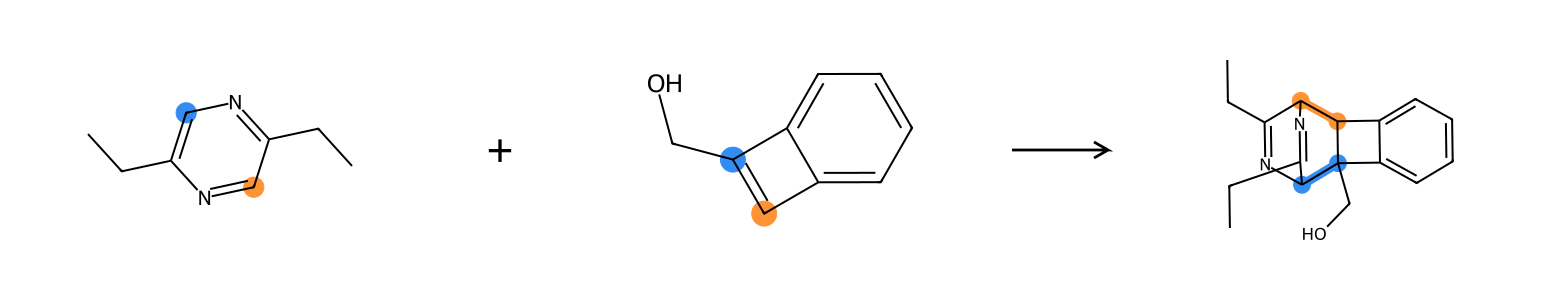

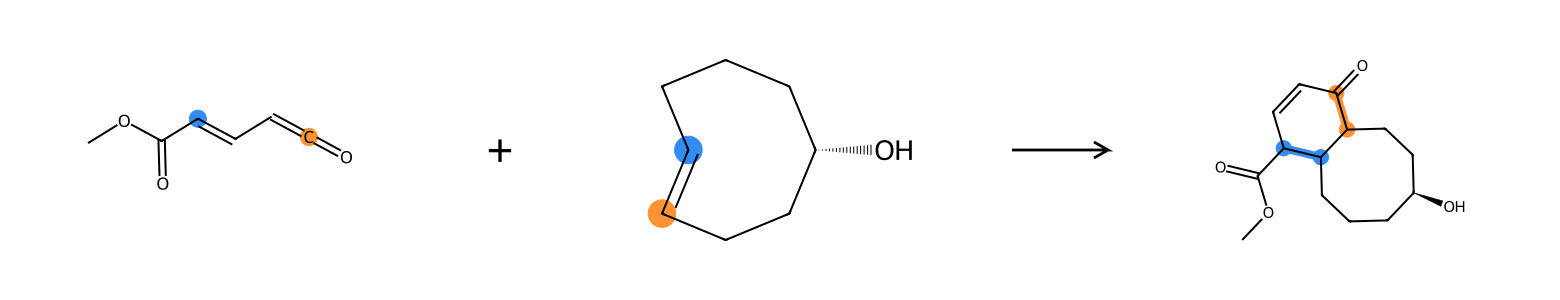

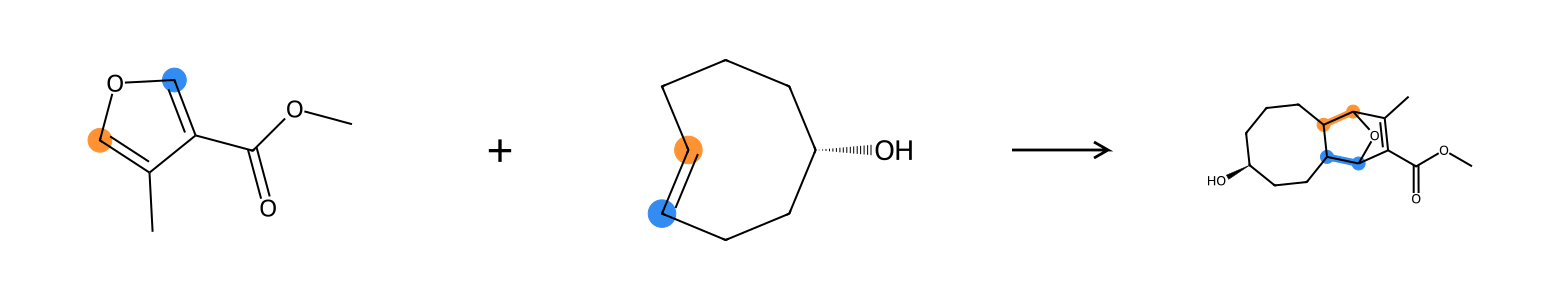

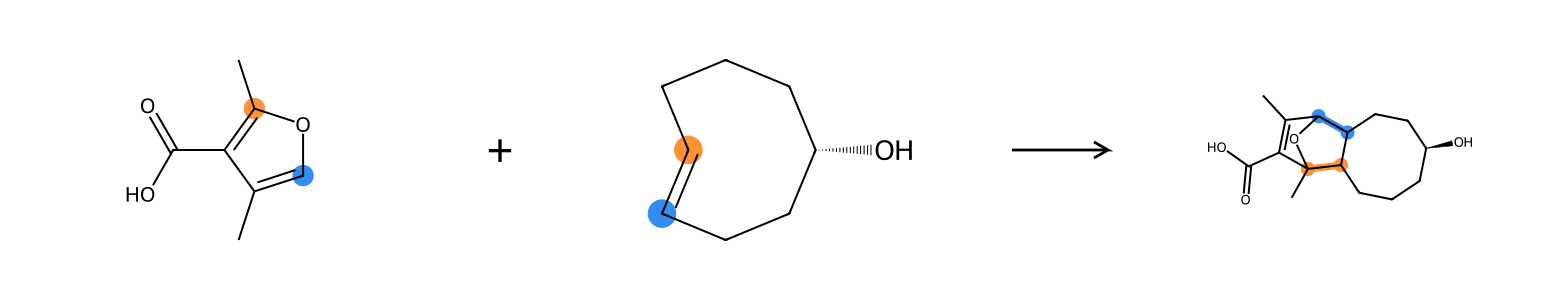

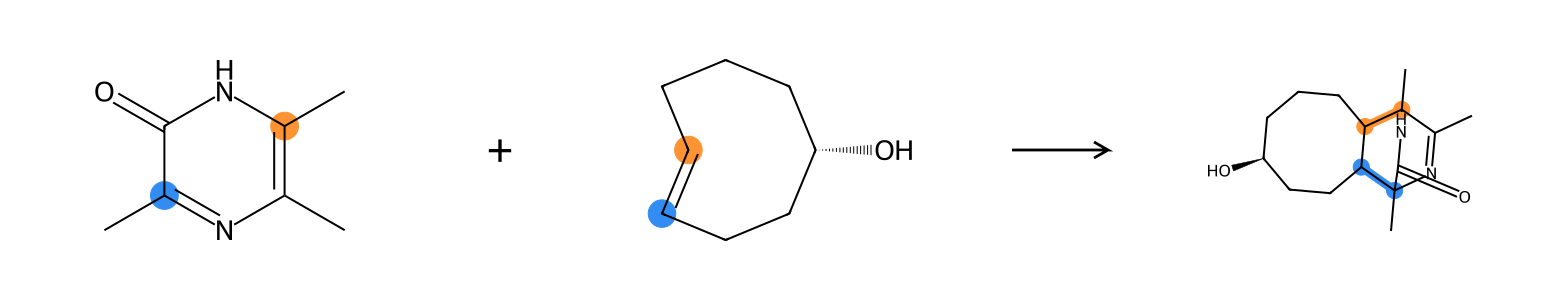

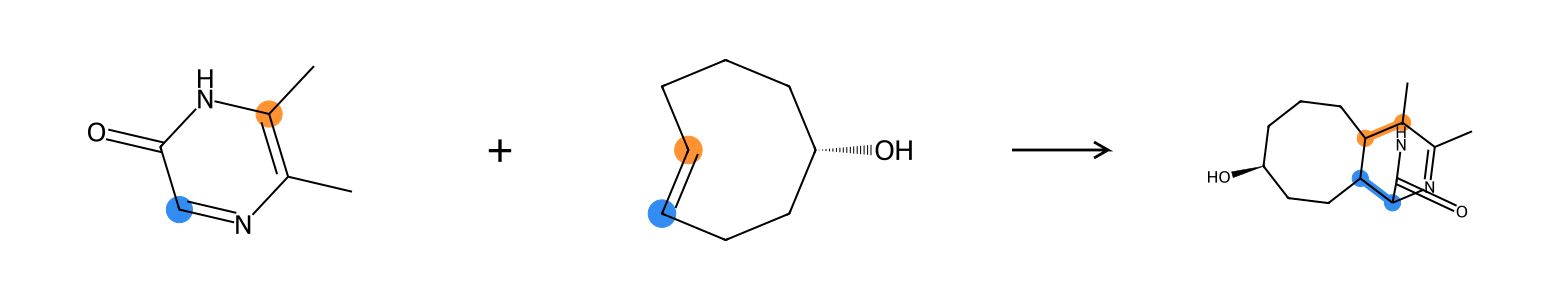

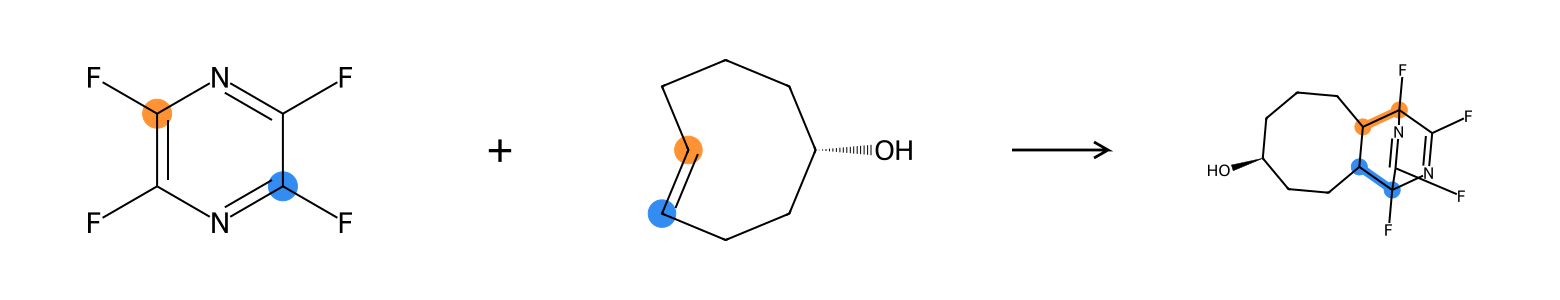

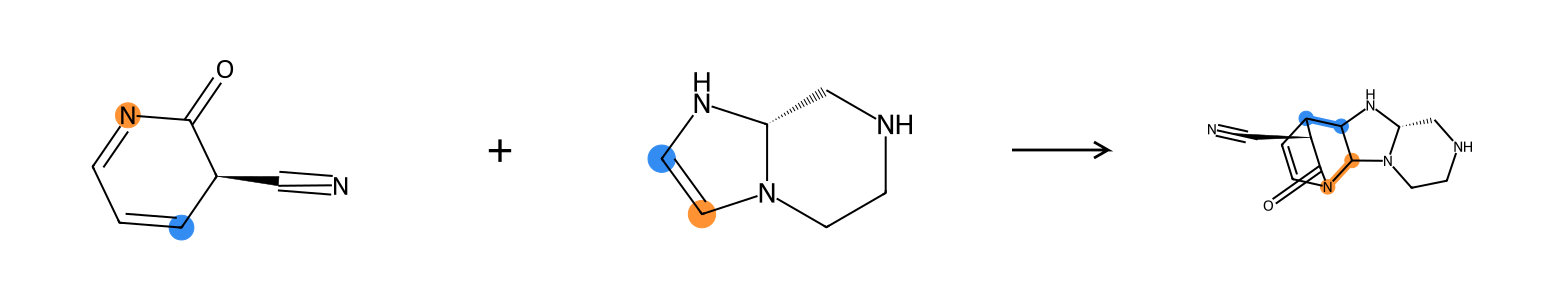

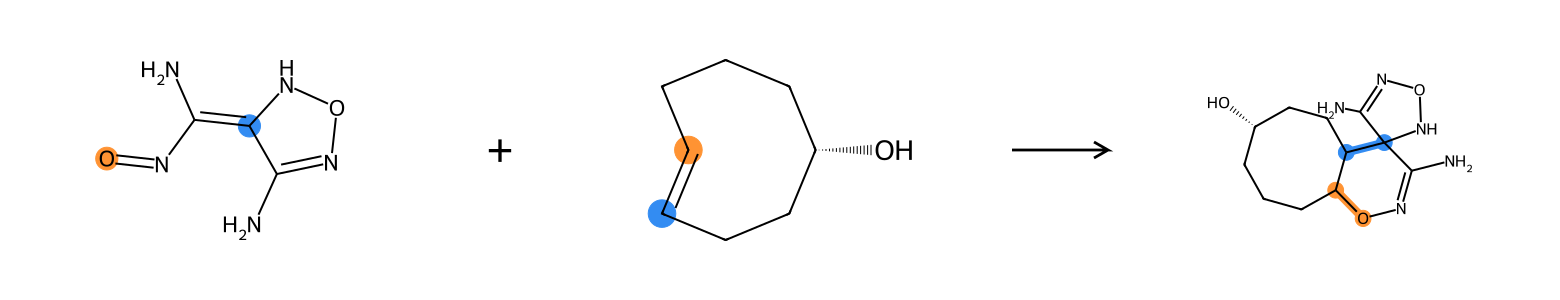

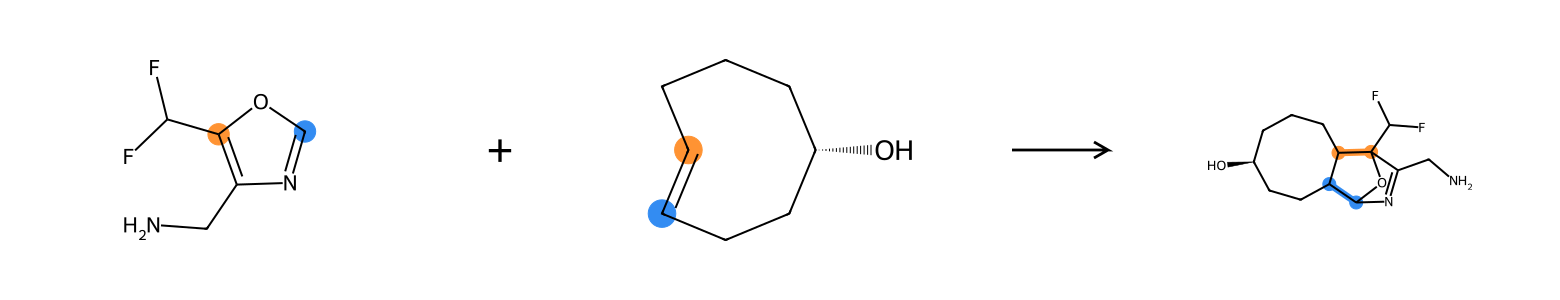

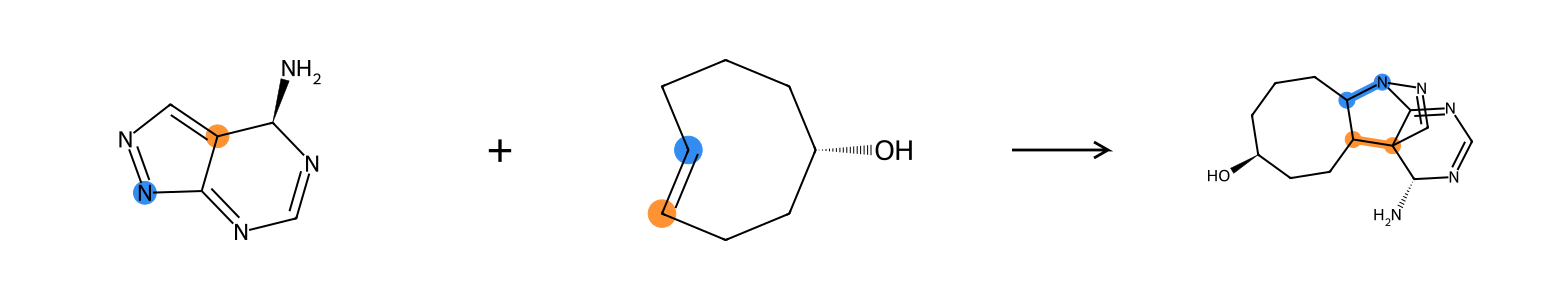

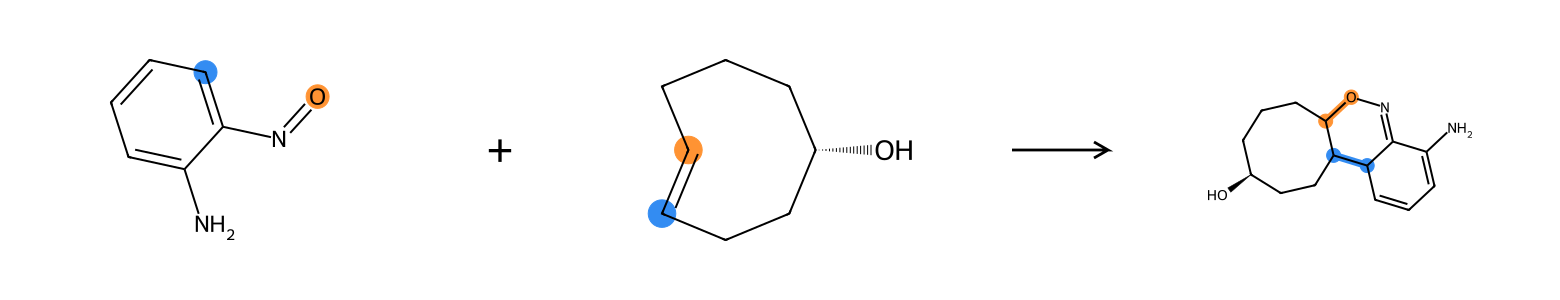

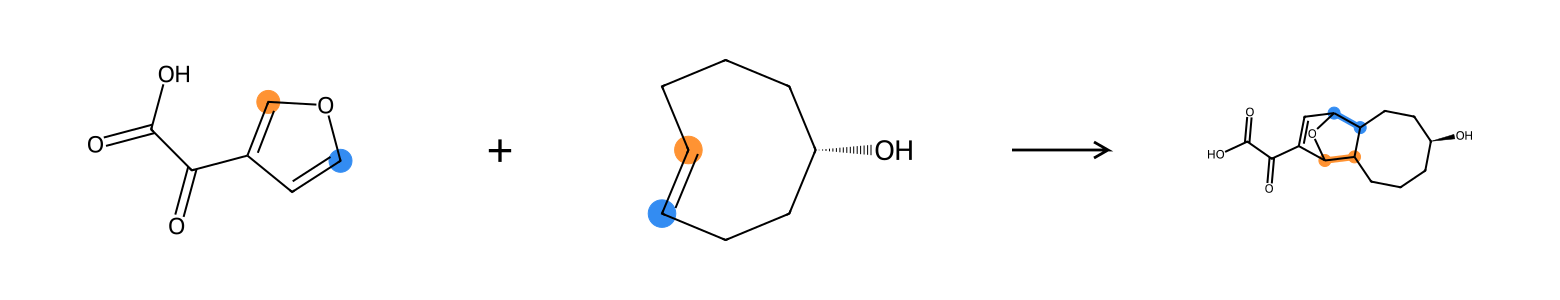

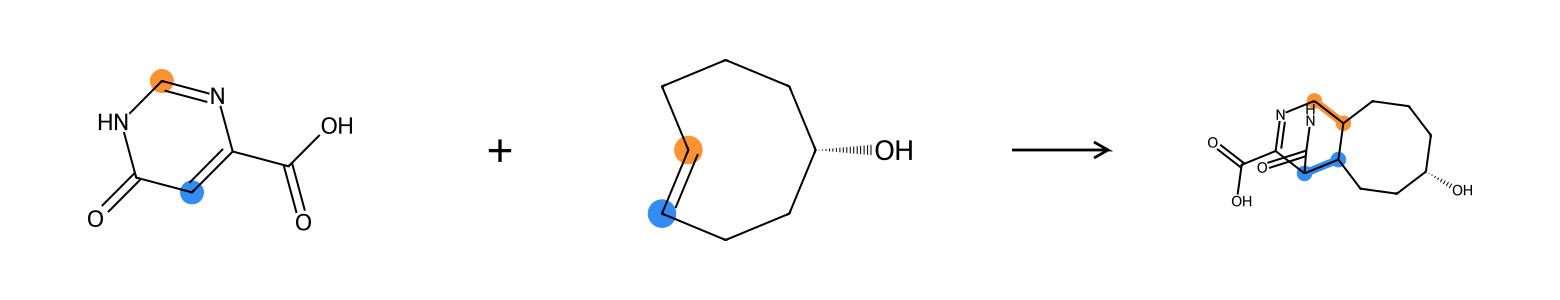

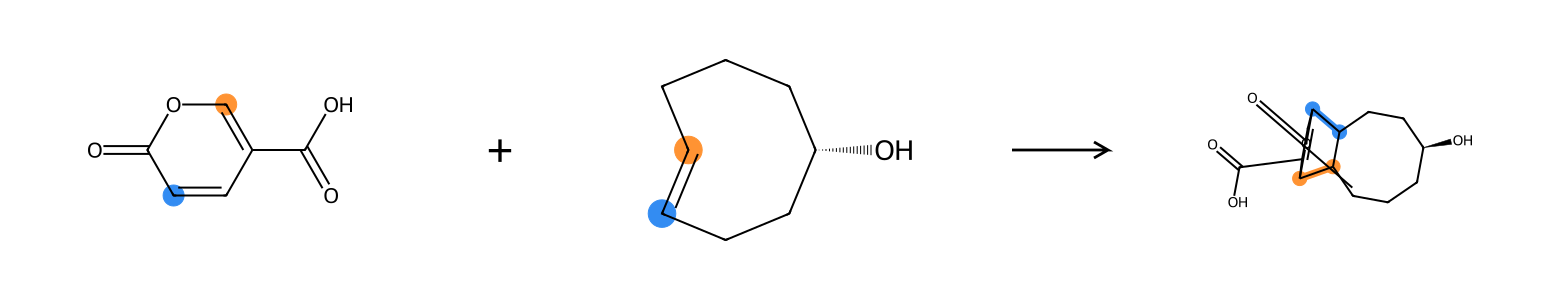

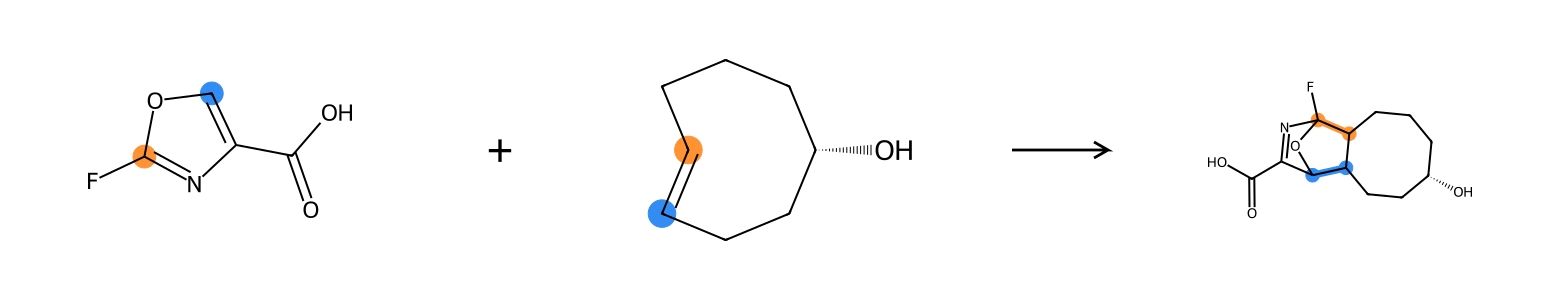

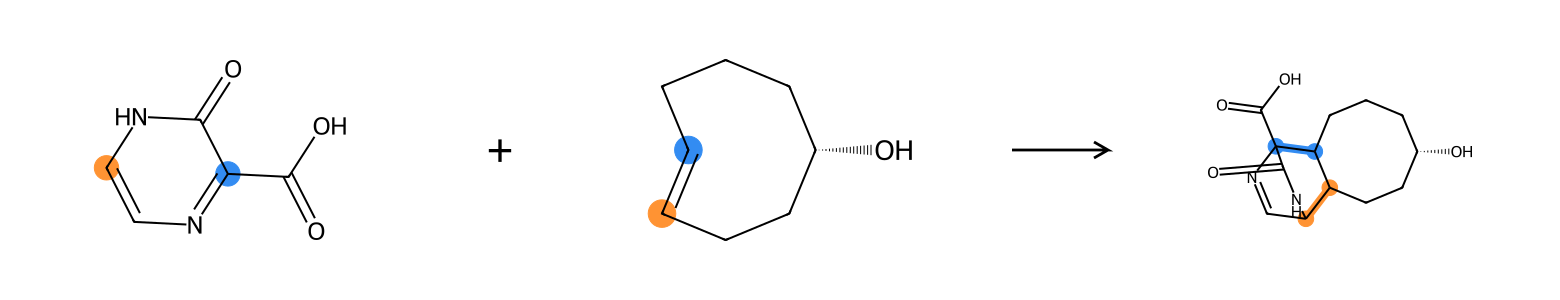

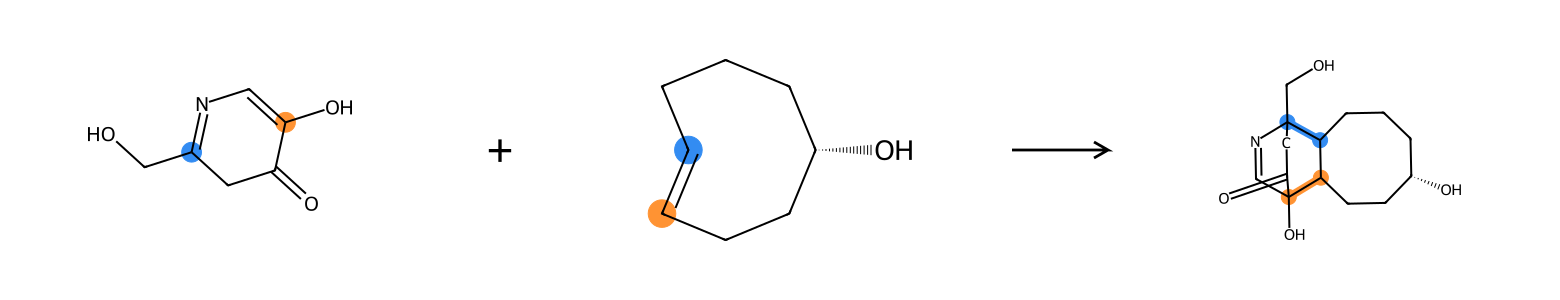

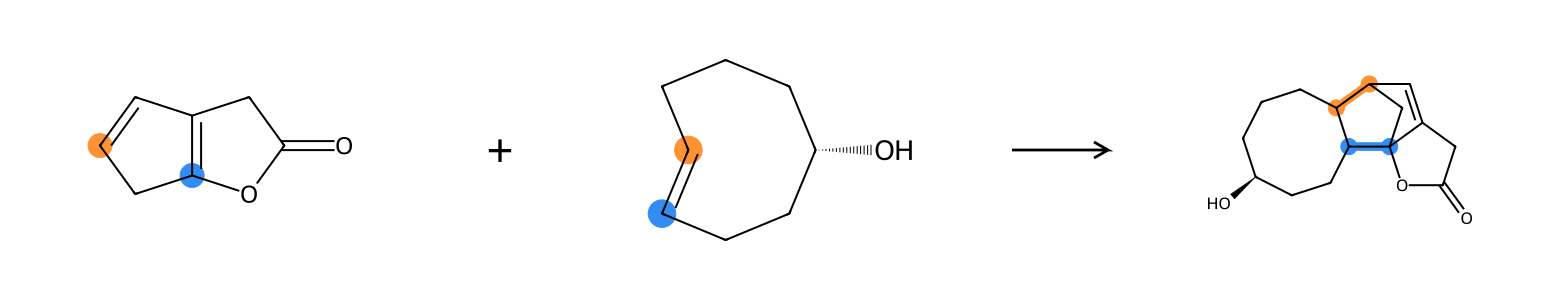

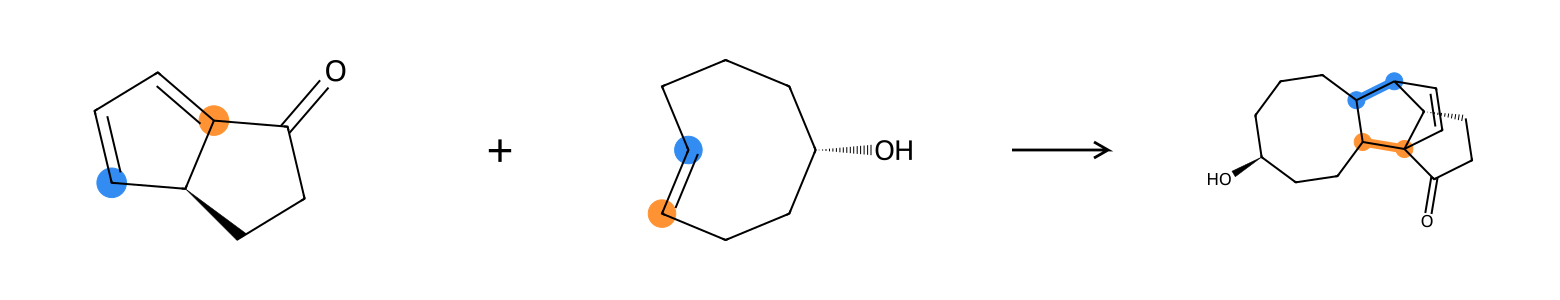

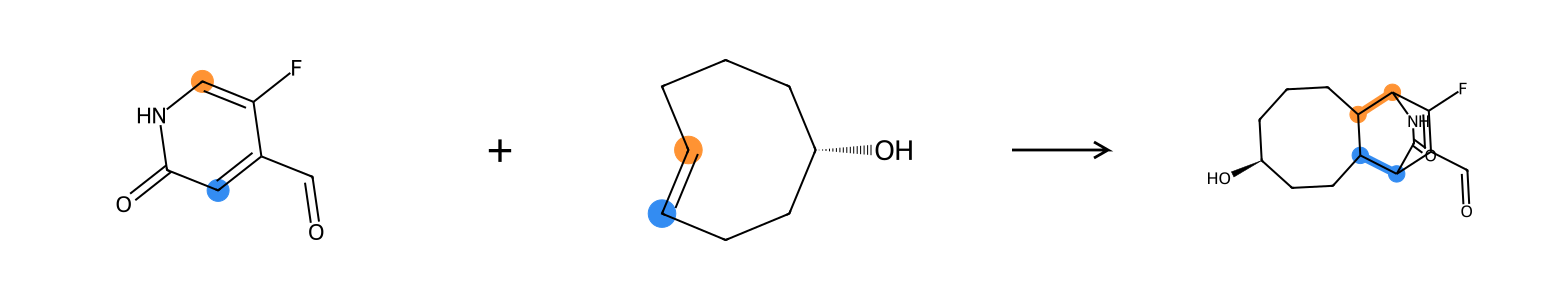

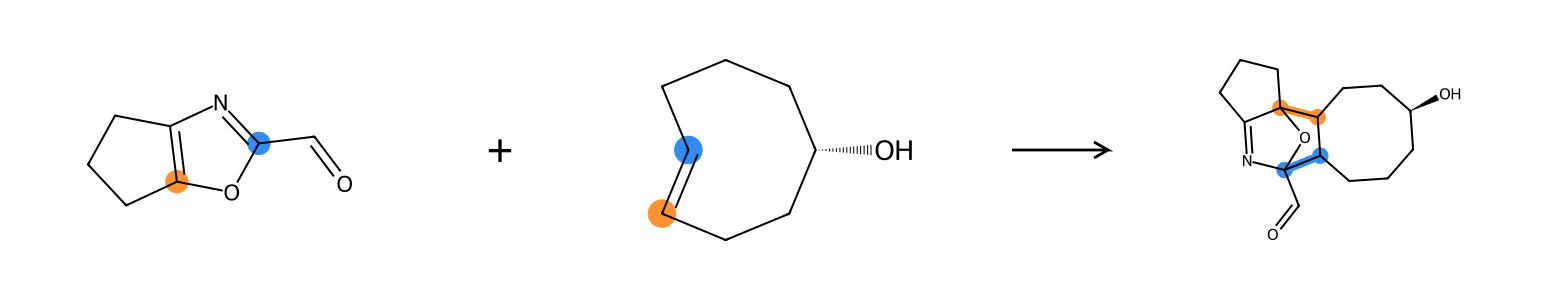

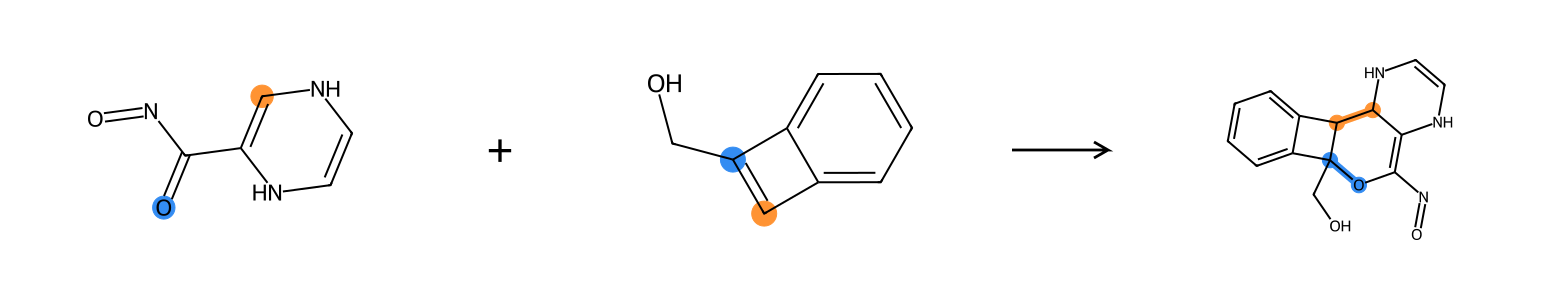

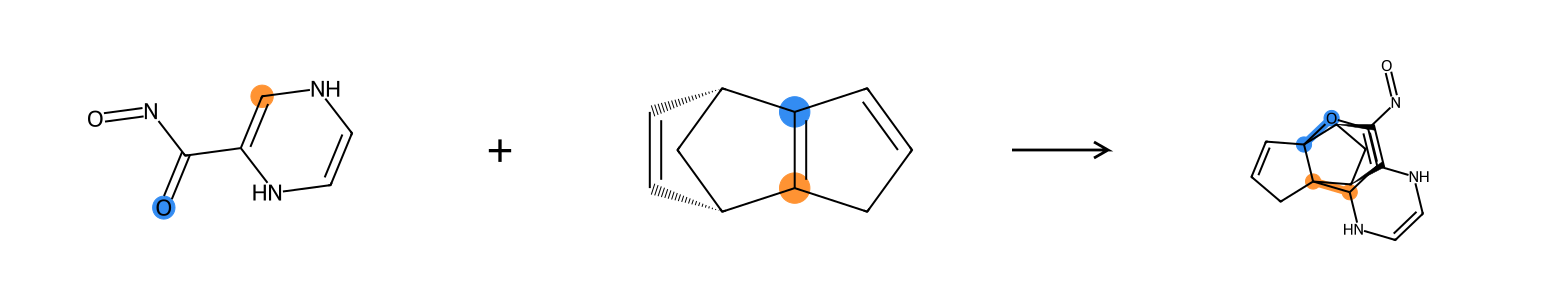

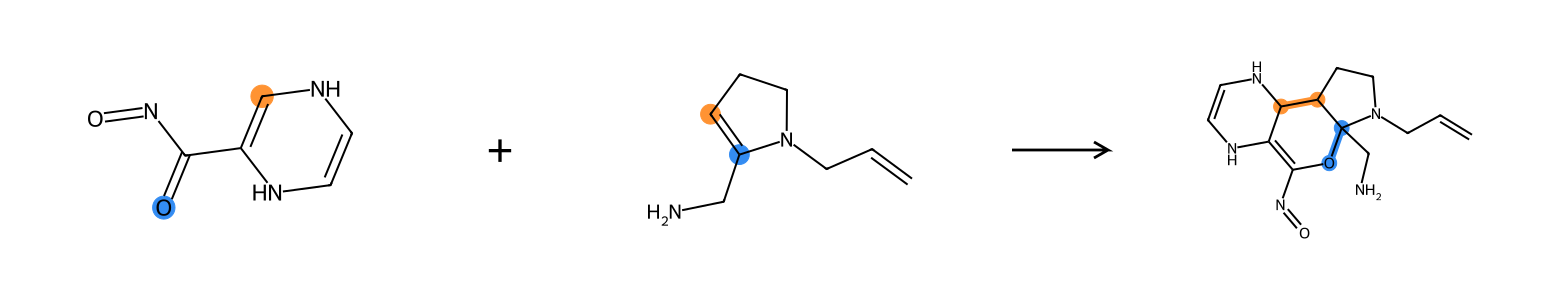

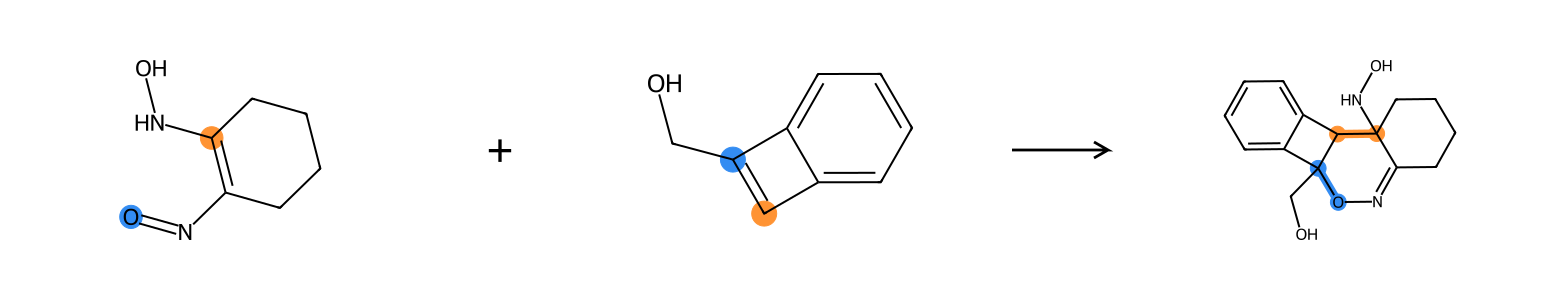

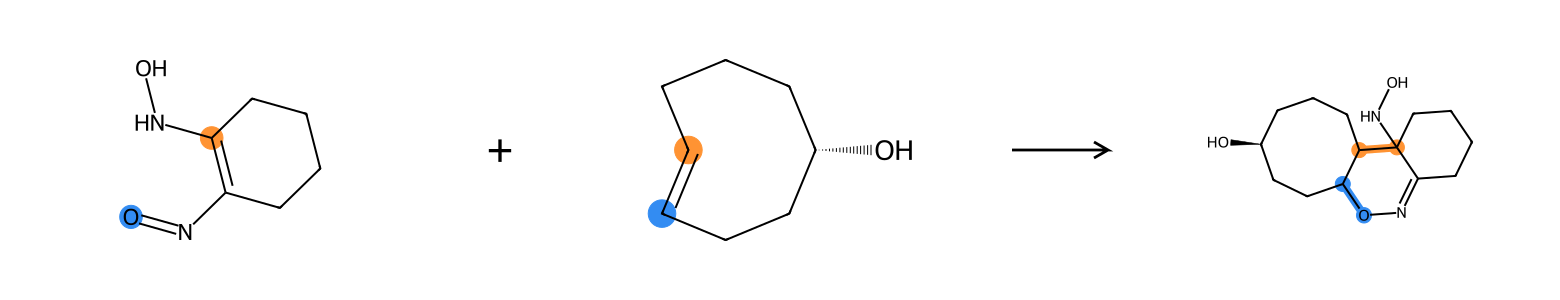

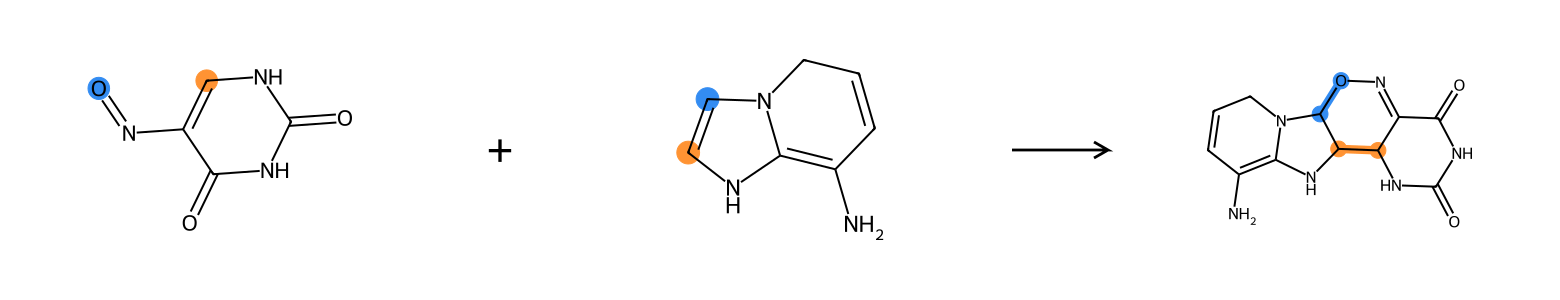

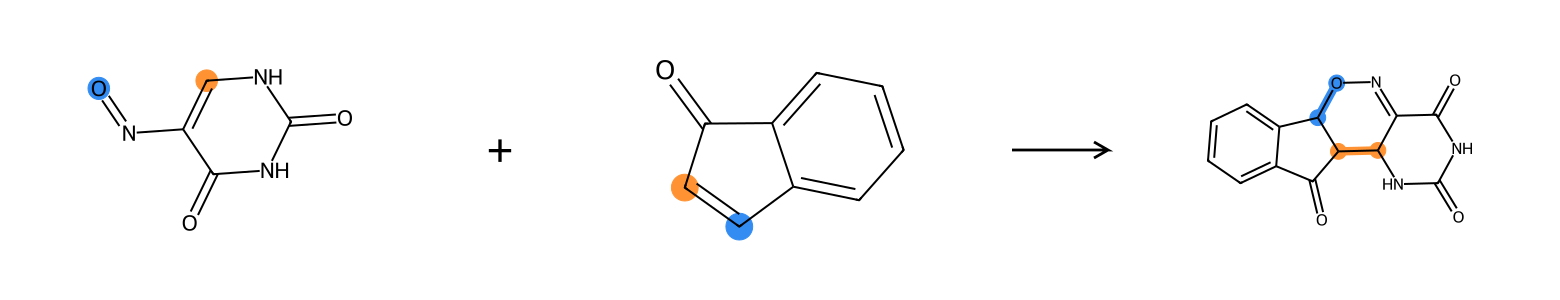

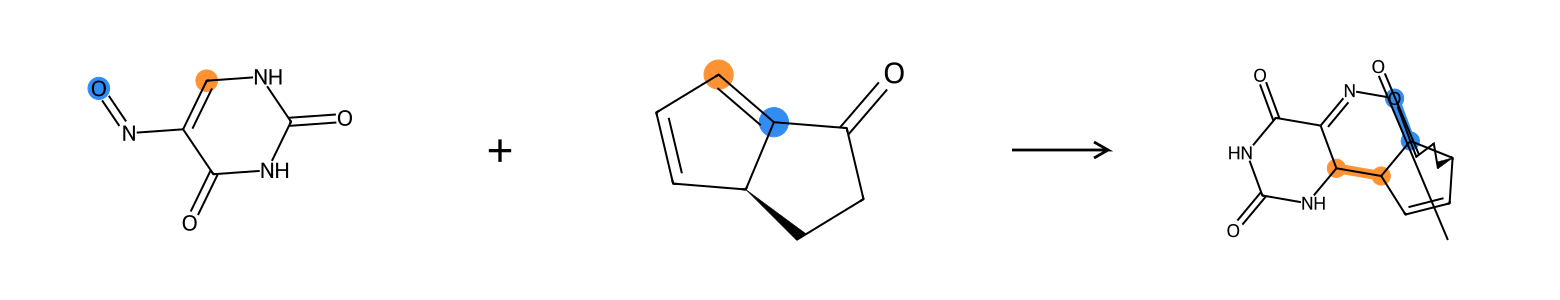

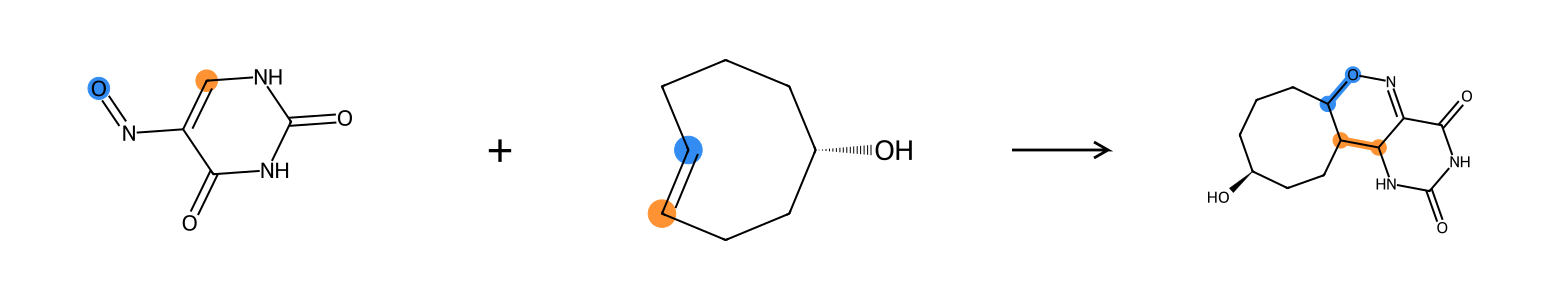

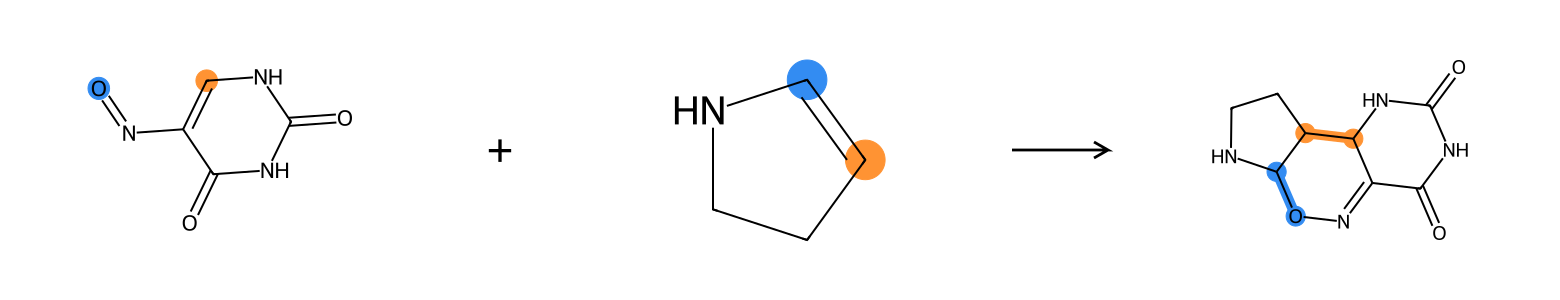

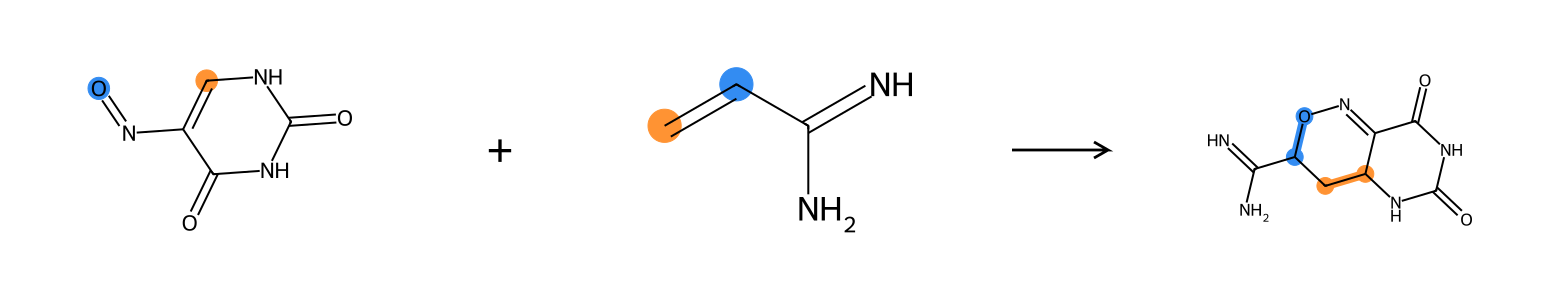

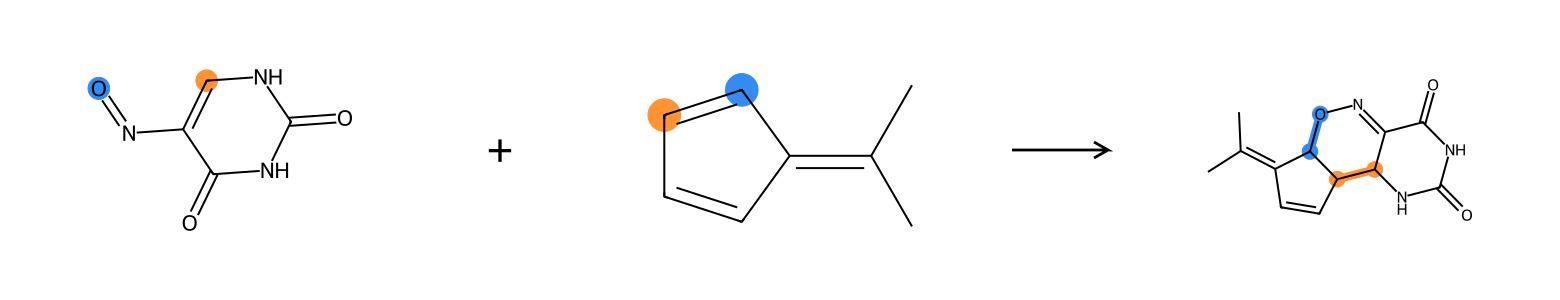

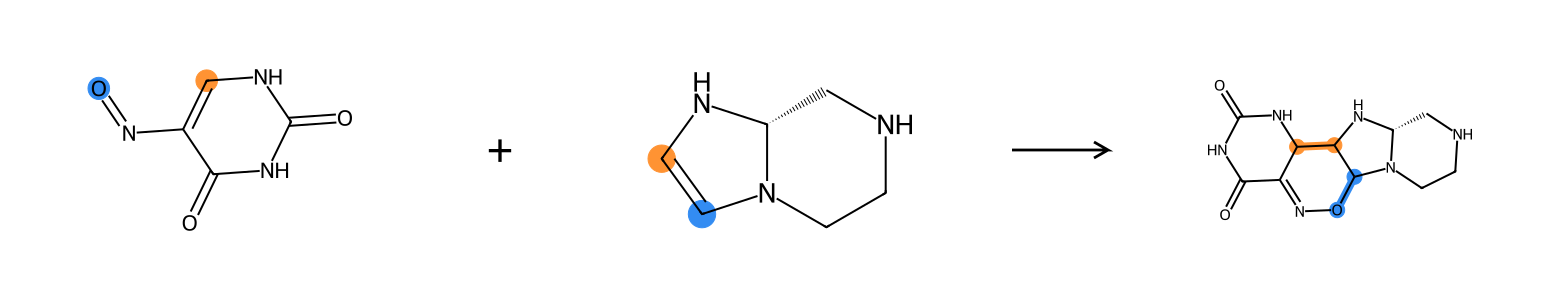

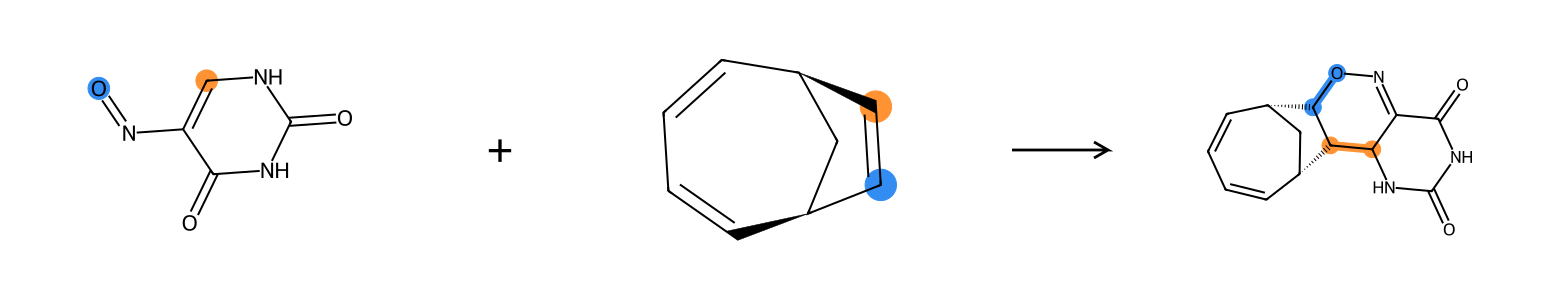

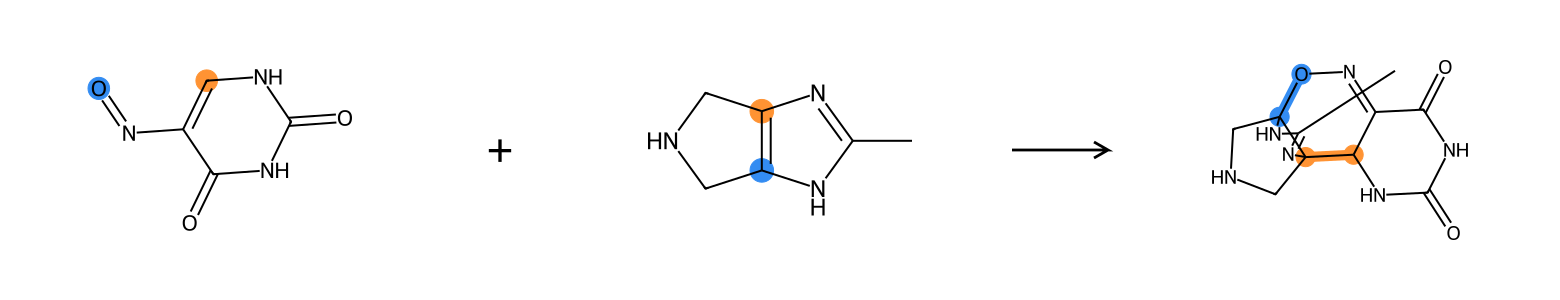

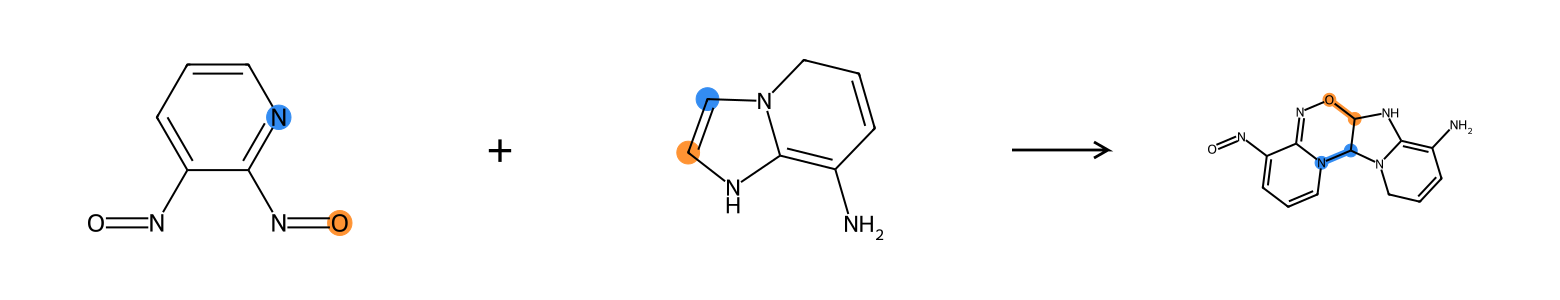

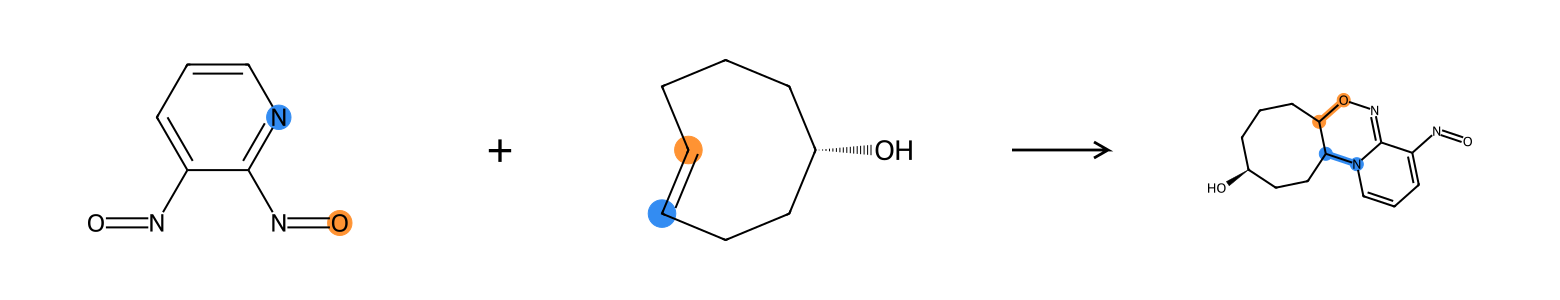

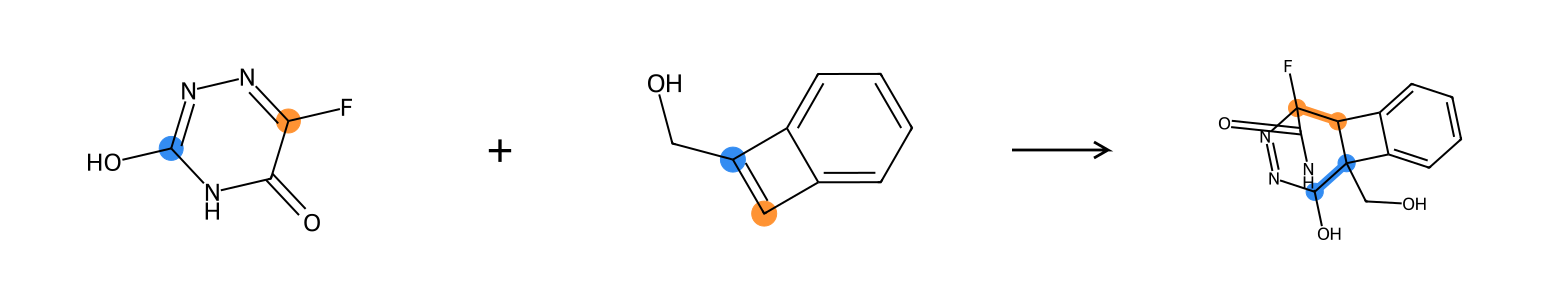

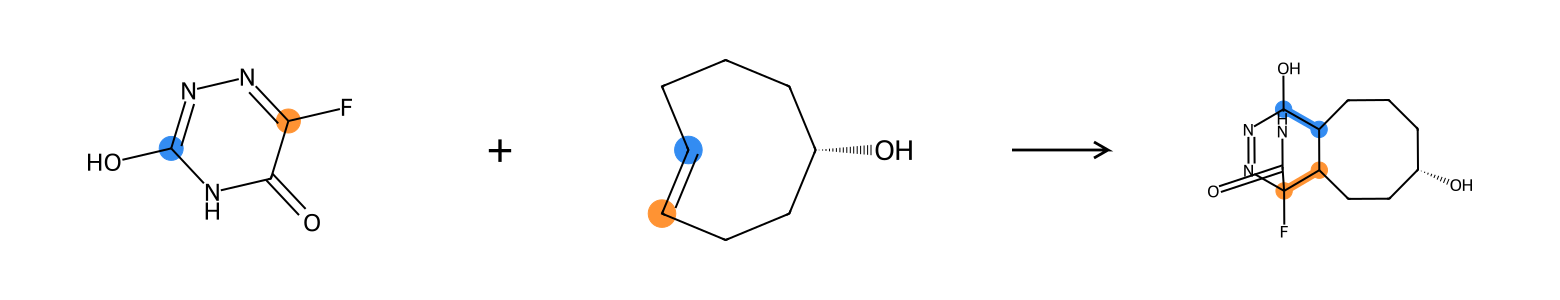

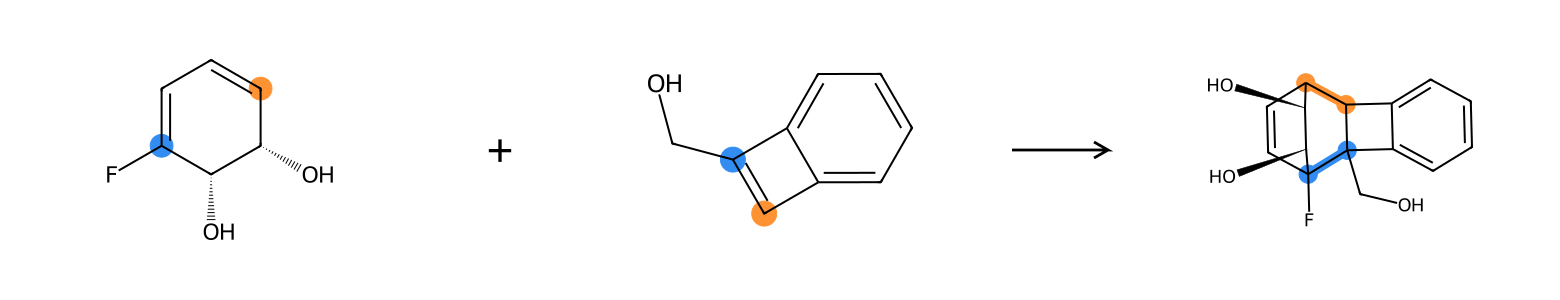

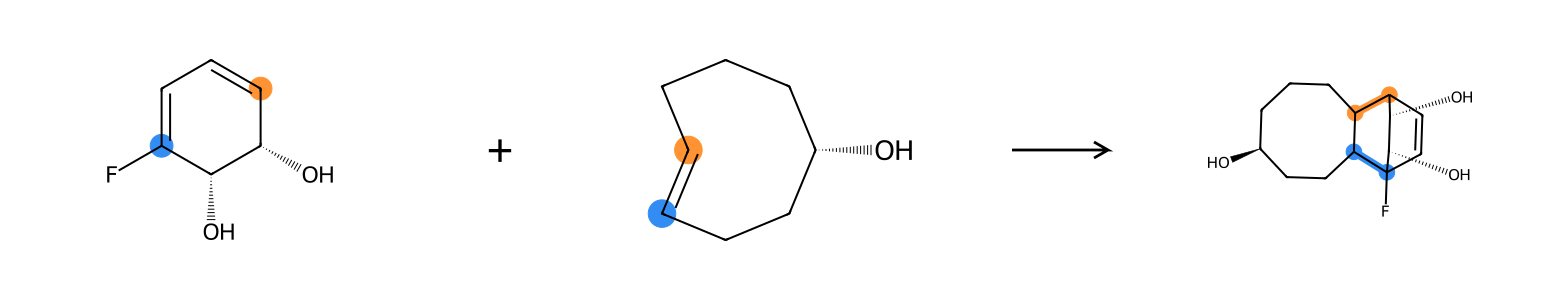

Exported 84 SVG drawings, index.html, and manifest.csv to: D:\OneDrive_all\OneDrive\Work\work_part\9.CycloAddGenerator\Data\Predict_DI\5_DI_selected_reaction_drawings


In [4]:
def molecule_svg(mol, formed):
    drawing = Chem.Mol(mol)
    atom_colors, bond_colors = {}, {}
    for pair, color in zip(formed, COLORS):
        for atom in drawing.GetAtoms():
            if atom.GetAtomMapNum() in pair:
                atom_colors[atom.GetIdx()] = color
        for bond in drawing.GetBonds():
            maps = tuple(sorted((bond.GetBeginAtom().GetAtomMapNum(),
                                 bond.GetEndAtom().GetAtomMapNum())))
            if maps == tuple(pair):
                bond_colors[bond.GetIdx()] = color
    if not SHOW_ATOM_MAP_NUMBERS:
        for atom in drawing.GetAtoms():
            atom.SetAtomMapNum(0)
    assert all(a.GetAtomicNum() != 1 for a in drawing.GetAtoms())
    rdDepictor.Compute2DCoords(drawing)
    drawing = rdMolDraw2D.PrepareMolForDrawing(drawing, addChiralHs=False)
    drawer = rdMolDraw2D.MolDraw2DSVG(PANEL_WIDTH, PANEL_HEIGHT)
    drawer.drawOptions().prepareMolsBeforeDrawing = False
    drawer.drawOptions().addStereoAnnotation = False
    drawer.drawOptions().useBWAtomPalette()
    drawer.drawOptions().flagCloseContactsDist = 0
    drawer.drawOptions().padding = MOLECULE_PADDING
    drawer.DrawMolecule(drawing, highlightAtoms=list(atom_colors),
                        highlightBonds=list(bond_colors),
                        highlightAtomColors=atom_colors, highlightBondColors=bond_colors)
    drawer.FinishDrawing()
    return drawer.GetDrawingText()


def reaction_svg(record):
    width = PANEL_WIDTH * 3 + PANEL_GAP * 2
    fragments = []
    for i, mol in enumerate(record["mols"]):
        element = ET.fromstring(molecule_svg(mol, record["formed"]))
        element.set("x", str(i * (PANEL_WIDTH + PANEL_GAP)))
        element.set("y", "0")
        fragments.append(ET.tostring(element, encoding="unicode"))
    center_y = PANEL_HEIGHT / 2
    plus_x = PANEL_WIDTH + PANEL_GAP / 2
    arrow_x = 2 * PANEL_WIDTH + PANEL_GAP + 12
    arrow_length = PANEL_GAP - 24
    return (f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" '
            f'height="{PANEL_HEIGHT}" viewBox="0 0 {width} {PANEL_HEIGHT}">'
            '<rect width="100%" height="100%" fill="white"/>'
            + "".join(fragments)
            + f'<text x="{plus_x}" y="{center_y}" '
              'text-anchor="middle" dominant-baseline="central" '
              'font-family="Arial, sans-serif" font-size="46" fill="black">+</text>'
            + f'<path d="M {arrow_x} {center_y} h {arrow_length} '
              'l -14 -8 m 14 8 l -14 8" stroke="black" fill="none" stroke-width="2.8"/>'
            + '</svg>')


if EXPORT_SVG:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
manifest, gallery = [], []
for record in records:
    row, position = record["row"], record["position"]
    identifier = f"{int(row['Diene_Index']):05d}_{int(row['Ene_Index']):05d}_{int(row['Structure_Id']):05d}"
    filename = f"{position:03d}_{identifier}.svg"
    svg = reaction_svg(record)
    caption = (f"{position:02d}/{len(records)} | index={row.get('index', '')} | {identifier} | "
               f"{record['source']} | site assignments={record['site_assignment_count']}")
    if position - 1 in range(*slice(START, STOP).indices(len(records))):
        display(HTML(f"<p><strong>{escape(caption)}</strong></p>"))
        display(SVG(svg))
    if EXPORT_SVG:
        (OUTPUT_DIR / filename).write_text(svg, encoding="utf-8")
    gallery.append(f'<section><h3>{escape(caption)}</h3><img src="{filename}" '
                   f'style="width:100%;max-width:{PANEL_WIDTH * 3 + PANEL_GAP * 2}px"/></section>')
    diene, ene, product = record["mols"]
    manifest.append(dict(csv_row=position, selection_index=row.get("index", ""),
                         Diene_Index=row["Diene_Index"], Ene_Index=row["Ene_Index"],
                         Structure_Id=row["Structure_Id"], Title=row["Title"],
                         mapping_source=record["source"],
                         site_assignment_count=record["site_assignment_count"],
                         formed_bonds=json.dumps(record["formed"]),
                         reaction_aam=(Chem.MolToSmiles(diene) + "." + Chem.MolToSmiles(ene)
                                       + ">>" + Chem.MolToSmiles(product)), svg_file=filename))
if EXPORT_SVG:
    with (OUTPUT_DIR / "manifest.csv").open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(manifest[0]))
        writer.writeheader()
        writer.writerows(manifest)
    html = ('<!doctype html><html><head><meta charset="utf-8"><title>Selected DI reactions</title>'
            '<style>body{font-family:Arial;margin:24px}section{break-inside:avoid;border-bottom:1px solid #ddd}'
            'h3{font-size:14px}</style></head><body><h1>Selected DI reactions</h1>'
            '<p>Blue / orange: two newly formed bond pairs. Explicit H atoms removed. Atom and bond labels are black; only reaction sites are colored. R/S annotations are hidden.</p>'
            + "".join(gallery) + '</body></html>')
    (OUTPUT_DIR / "index.html").write_text(html, encoding="utf-8")
    print(f"Exported {len(manifest)} SVG drawings, index.html, and manifest.csv to: {OUTPUT_DIR}")